# Hydraulic subdomains: split a rain-on-grid parent at normal-depth locations

This notebook splits the FEMA eBFE **Salt Draw** model into hydraulic
subdomains. The model is HUC-8 13070004: one 2D rain-on-grid area of 794,234
cells, built in HEC-RAS 6.4.1. The notebook then builds two subdomains, a
small headwater and a larger main-stem subdomain, runs each as an independent
breakout model, and compares it with the parent.

**The method.** Putting a model boundary where normal depth can be assumed is
standard practice. What this workflow adds is a numerical way to find those
places, from the parent model itself:

1. **Channels and contributing areas** come from the terrain: TauDEM D8 stream
   links and their catchments (`RasTauDem`).
2. **Candidate boundaries** are lines across the valley at pour points (link
   outlets) and in short steps upstream. Each follows the parent's own largest
   downstream face volumes out to the wet edge.
3. **Each candidate is judged as a normal-depth boundary** in every event,
   against the parent's native `Face Flow` and cell stage. The comparison runs
   through the conveyance of the parent's own face property tables, at the best
   single friction slope (`RasSubdomain.find_split_lines`).
4. **Subdomain extents** are traced from the parent's cell-to-cell drainage and
   nested into tiers, upstream first (`RasSubdomain.build_subdomains`).
5. **Breakout models** keep the parent's exact cells (cookie cut). Each gets a
   Normal Depth outlet at the fitted slope, Normal Depth along the parent
   perimeter, and an inflow hydrograph from each subdomain upstream
   (`plan_breakouts`, `apply_breakouts`, `validate_breakouts`).

A subdomain with simple normal-depth boundaries is a faithful breakout only
where normal depth holds. Flat, backwater-controlled reaches yield few
accepted lines, and the search reports that rather than forcing a split.

**Same version as the delivered model.** Everything runs in HEC-RAS 6.4.1, the
version the model was built and delivered in. The delivered mesh is used as
is. (HEC-RAS 6.6 rejects 48 of its cells, which have more than eight sides, so
a 6.6 workflow would first have to re-mesh the parent and run it again.)

**Scope.** This is a proof of concept. It solves **two subdomains**, a
headwater and a larger main-stem subdomain, and compares each with the parent;
the full-HUC tiered run and the parity proof come later. For this HUC model,
the whole HUC run as six children plus the main channel reproduced the parent's
1% AEP maximum WSE within 0.008 ft on the main channel (p95 over 466,000 cells),
and the outlet peak within 0.2%.

**Prerequisites.** Windows with HEC-RAS 6.4.1 installed and its terms of use
accepted, TauDEM with MPI, and the Python packages imported in the first code
cell. Optional environment variables (first code cell) point the notebook at an
existing download, an organized delivery, existing parent Face Flow runs and the
work folder.

**What is reused and what is rebuilt.** The organized delivery, the parent
Face Flow runs and the TauDEM outputs are reused when their files exist under
`WORK_ROOT`, so download, organization and the parent runs happen once per
machine. The split-line search runs every time. Breakout authoring replaces any
existing breakout folder, and the figures under
`examples/assets/237_hydraulic_subdomain_breakout` are overwritten. The saved
outputs come from a run that reused existing parent Face Flow runs and TauDEM
outputs, then searched, authored and ran every breakout.

**Terms.** WSE is water surface elevation, in feet in the delivered model's
vertical datum. AEP is annual exceedance probability: the 1% and 0.2% AEP events
are the delivered plans `1pct` (plan 01) and `0_2pct` (plan 02). NSE is the
Nash-Sutcliffe efficiency of the breakout's outlet hydrograph against the
parent's, and IoU is the intersection over union of the wet extents. p50, p95
and p99 are percentiles of the absolute difference. Times are hours from the
start of the simulation.

In [1]:
import os
import shutil
import sys
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "ras_commander").is_dir() and (candidate / "setup.py").exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ras_commander import RasCmdr, RasPlan, RasPrj, init_ras_project
from ras_commander.RasTcu import RasTcu
from ras_commander.sources.federal.ebfe_models import RasEbfeModels
from ras_commander.subdomain import RasSubdomain, SplitLineCriteria
from ras_commander.subdomain._parent import read_geometry, same_geometry
from ras_commander.terrain import RasTauDem

# Where every stage writes; reruns reuse what is already there.
WORK_ROOT = Path(os.environ.get("RAS_SUBDOMAIN_WORK", Path.home() / "ras-commander-work" / "237_salt_draw"))
# Optional: a local 13070004_Models.zip, a folder holding it, or the extracted delivery.
# Without it the organizer downloads the 67 GB FEMA archive into WORK_ROOT/download.
EBFE_SOURCE = os.environ.get("SALT_DRAW_EBFE_SOURCE")
ORGANIZED = Path(os.environ.get("SALT_DRAW_ORGANIZED", WORK_ROOT / "01_organized"))
# Optional: existing HEC-RAS 6.4.1 runs of the delivered plans 01 (1% AEP) and 02 (0.2% AEP)
# with native Face Flow, separated by os.pathsep. Without them the notebook runs both once.
PARENT_FACEFLOW_HDFS = [p for p in os.environ.get("SALT_DRAW_PARENT_FACEFLOW_HDFS", "").split(os.pathsep) if p]
HECRAS_VERSION = "6.4.1"  # the delivered model's version
NUM_CORES = int(os.environ.get("RAS_SUBDOMAIN_CORES", "2"))

PARENT_ROOT = WORK_ROOT / "02_parent"
TAUDEM_DIR = WORK_ROOT / "03_taudem"
BREAKOUT_DIR = WORK_ROOT / "05_breakout"
FIG_DIR = REPO_ROOT / "examples" / "assets" / "237_hydraulic_subdomain_breakout"
for folder in (WORK_ROOT, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("work root:", WORK_ROOT)
print("TauDEM:", RasTauDem.get_taudem_info()["executables"]["StreamNet"])
print("HEC-RAS", HECRAS_VERSION, "TCU:", RasTcu.status(ras_version=HECRAS_VERSION).reason)

work root: G:\clb-gen3-scratch\237_salt_draw
TauDEM: C:\Program Files\TauDEM\TauDEM5Exe\StreamNet.exe
HEC-RAS 6.4.1 TCU: accepted


## 1. Organize the eBFE delivery

`RasEbfeModels.organize_salt_draw` checks the archive identity and extracts the
RAS submittal. The delivered result HDFs (9 GB each) are left in the archive:
they hold no native `Face Flow`, so this workflow does not use them.

In [2]:
project_dir = ORGANIZED / "RAS Model" / "RAS_Submittal"
if not (project_dir / "Input" / "SLDR_004.prj").is_file():
    t0 = time.time()
    RasEbfeModels.organize_salt_draw(
        downloaded_folder=EBFE_SOURCE or WORK_ROOT / "download",
        output_folder=ORGANIZED,
        output_plans=[],
        include_hms=False,
    )
    print(f"organized in {(time.time() - t0) / 60:.1f} min")
delivered = RasPrj()
init_ras_project(project_dir / "Input", HECRAS_VERSION, ras_object=delivered, load_results_summary=False)
display(delivered.plan_df[["plan_number", "Plan Title", "geometry_number", "unsteady_number"]])

2026-10-25 19:32:42 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-25 19:32:42 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-25 19:32:42 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


2026-10-25 19:32:42 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

,plan_number,Plan Title,geometry_number,unsteady_number
0,01,SLDR_004_1pct,02,01
1,02,SLDR_004_0_2pct,02,02
2,03,SLDR_004_10pct,02,03
3,04,SLDR_004_4pct,02,04
4,05,SLDR_004_2pct,02,05
5,06,SLDR_004_1plu,02,06
6,07,SLDR_004_1min,02,07


## 2. Run the delivered parent once with native Face Flow

The split-line search needs native `Face Flow`, which the delivered results do
not include. The parent working copy is the delivered project without its
result HDFs. `RasPlan.add_hdf_output_variable` adds `Face Flow` to plans `01`
(1% AEP) and `02` (0.2% AEP); nothing else changes. Each plan then runs once in
6.4.1: about 13 h each on 2 cores in the research runs.

If `SALT_DRAW_PARENT_FACEFLOW_HDFS` names existing 6.4.1 Face Flow runs of
those plans, the notebook uses them instead. Either way it first proves that
every run used the delivered mesh.

In [3]:
parent_dir = PARENT_ROOT / "RAS_Submittal"
if not (parent_dir / "Input" / "SLDR_004.prj").is_file():
    shutil.copytree(project_dir, parent_dir,
                    ignore=lambda folder, names: [n for n in names if n.lower().endswith((".p01.hdf", ".p02.hdf"))])
parent = RasPrj()
init_ras_project(parent_dir / "Input", HECRAS_VERSION, ras_object=parent, load_results_summary=False)
if PARENT_FACEFLOW_HDFS:
    parent_hdfs = [Path(p) for p in PARENT_FACEFLOW_HDFS]
    print("using existing 6.4.1 Face Flow runs:", *[p.name for p in parent_hdfs])
else:
    parent_hdfs = []
    for plan in ("01", "02"):
        hdf = parent_dir / "Input" / f"SLDR_004.p{plan}.hdf"
        if not hdf.is_file():
            RasPlan.add_hdf_output_variable(plan, "Face Flow", ras_object=parent)
            t0 = time.time()
            assert RasCmdr.compute_plan(plan, ras_object=parent, num_cores=NUM_CORES, verify=True)
            print(f"plan {plan} computed in {(time.time() - t0) / 3600:.1f} h")
        parent_hdfs.append(hdf)
delivered_geometry = read_geometry(parent_dir / "Input" / "SLDR_004.g02.hdf", "SLDR_004")
for hdf in parent_hdfs:
    assert same_geometry(read_geometry(hdf, "SLDR_004"), delivered_geometry), hdf
print(f"delivered mesh: {delivered_geometry.cell_count:,} cells, {len(delivered_geometry.face_cells):,} faces; "
      f"identical in all {len(parent_hdfs)} parent runs")

2026-10-25 19:32:43 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-25 19:32:43 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-25 19:32:43 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


2026-10-25 19:32:43 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

using existing 6.4.1 Face Flow runs: SLDR_004.p01.faceflow641.hdf SLDR_004.p02.faceflow641.hdf


delivered mesh: 794,234 cells, 1,846,384 faces; identical in all 2 parent runs


## 3. Delineate channels and catchments with TauDEM

The delivered 10 ft terrain is resampled to 100 ft for D8 delineation. Streams
begin at 0.5 sq mi. Each StreamNet link outlet is a pour point.

In [4]:
terrain_tif = parent_dir / "Terrain" / "Terrain.salt_draw_mosaic_max.tif"
streams_file, catchments_file = TAUDEM_DIR / "streams.parquet", TAUDEM_DIR / "catchments.parquet"
if not streams_file.is_file():
    t0 = time.time()
    taudem = RasTauDem.delineate(terrain_tif, TAUDEM_DIR, stream_area_sqmi=0.5, cell_size=100.0,
                                 num_processes=NUM_CORES, overwrite=True)
    taudem.streams.to_parquet(streams_file)
    taudem.catchments.to_parquet(catchments_file)
    print(f"TauDEM in {time.time() - t0:.0f} s")
streams, catchments = gpd.read_parquet(streams_file), gpd.read_parquet(catchments_file)
print(f"{len(streams):,} stream links; outlet link drains "
      f"{streams['contributing_area_sqmi'].max():,.0f} sq mi")

3,204 stream links; outlet link drains 1,204 sq mi


## 4. Find normal-depth split lines across the whole HUC

The search walks up from every pour point with at least 1 sq mi of
contributing area. It scores each candidate line in **both** events against
the project-engineer criteria of 2026-10-14 (`SplitLineCriteria`):

- both banks close;
- reverse flow is at most 5%;
- RMSE, peak error and loop width are each at most 0.5 ft;
- the best slope is within 1/3 to 3 times the TauDEM link slope;
- the line carries 80% to 120% of the contributing area's outflow.

A split line must pass in both events at its step and at a neighboring step.
Lines grow on the event with the most volume, the 0.2% AEP, so both events
judge the same faces.

In [5]:
t0 = time.time()
search = RasSubdomain.find_split_lines(parent_hdfs, streams, catchments, mesh_name="SLDR_004",
                                       criteria=SplitLineCriteria())
partition = RasSubdomain.build_subdomains(search)
print(f"search and partition in {(time.time() - t0) / 60:.1f} min; events {search.events}, "
      f"lines grown on {search.growth_event}")
candidates = search.candidates
print(f"{candidates['split_line_id'].nunique():,} pour points, {len(candidates):,} scored steps and events, "
      f"{int(candidates['passes'].sum()):,} passing, {len(search.split_lines)} split lines")
display(candidates.explode("failed_criteria").groupby("event")["failed_criteria"].value_counts()
        .unstack(0).rename_axis(None).fillna(0).astype(int))
subdomains = partition.subdomains
print(f"{len(subdomains) - 1} subdomains in {subdomains['tier'].max() - 1} tiers plus the remainder")

2026-10-25 19:33:40 - ras_commander.subdomain.RasSubdomain - INFO - Integrating event face volumes (2 events, 1846384 faces)


2026-10-25 19:50:40 - ras_commander.subdomain.RasSubdomain - INFO - 1304 pour points, 27188 walk-up steps


2026-10-25 19:53:55 - ras_commander.subdomain.RasSubdomain - INFO - 116 split lines from 54376 scored rows


search and partition in 26.4 min; events ('1pct', '0_2pct'), lines grown on 0_2pct
1,304 pour points, 54,376 scored steps and events, 2,877 passing, 116 split lines


event,0_2pct,1pct
LINE_OPEN,94,94
NORMAL_DEPTH_LOOP,3898,1849
NORMAL_DEPTH_PEAK,8046,5377
NORMAL_DEPTH_RMSE,3940,3386
NO_FLOW,73,142
OUTFLOW_SHARE,24221,23935
REVERSE_FLOW,167,202
SLOPE_RATIO,16041,19323


116 subdomains in 25 tiers plus the remainder


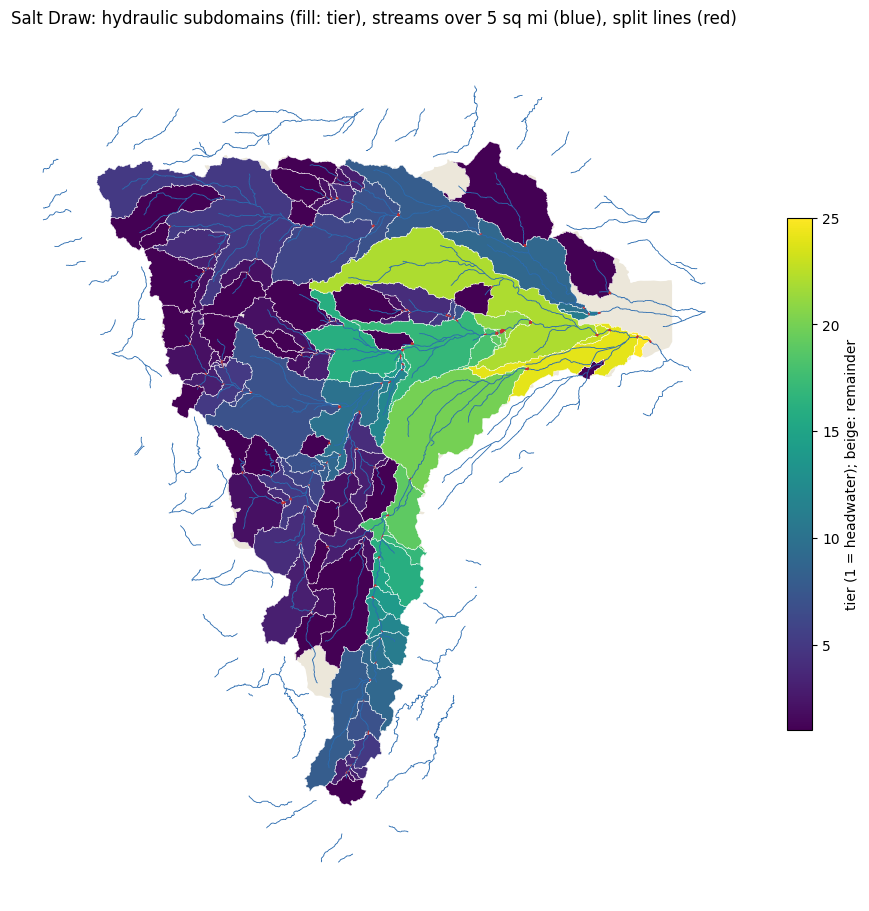

In [6]:
fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
tiers = subdomains[subdomains["subdomain_id"] != partition.remainder_id]
subdomains[subdomains["subdomain_id"] == partition.remainder_id].plot(ax=ax, color="#ECE7DA", edgecolor="none")
tiers.plot(ax=ax, column="tier", cmap="viridis", edgecolor="white", linewidth=0.3, legend=True,
           legend_kwds={"label": "tier (1 = headwater); beige: remainder", "shrink": 0.6})
streams[streams["contributing_area_sqmi"] >= 5].to_crs(subdomains.crs).plot(ax=ax, color="#2B6CB0", linewidth=0.6)
search.split_lines.plot(ax=ax, color="#C53030", linewidth=2.0)
ax.set_title("Salt Draw: hydraulic subdomains (fill: tier), streams over 5 sq mi (blue), split lines (red)")
ax.set_axis_off()
fig.savefig(FIG_DIR / "01_subdomains.png", dpi=130)
plt.show()

## 5. Choose one headwater subdomain

A headwater subdomain (tier 1) has no subdomain upstream, so the parent's
rainfall is its only forcing. The choice is rule-based: no labels (in
particular no closed-edge leakage over 5% in either event), between 3 and
15 sq mi, and the lowest closed-edge exchange.

In [7]:
leak = [f"leak_fraction_{e}" for e in search.events]
pick = subdomains[(subdomains["tier"] == 1) & subdomains["labels"].apply(len).eq(0)
                  & subdomains["area_sqmi"].between(3, 15)].copy()
pick["worst_leak"] = pick[leak].max(axis=1)
pick = pick.sort_values("worst_leak")
display(pick[["subdomain_id", "cell_count", "area_sqmi", *leak]].head())
HEADWATER = pick["subdomain_id"].iloc[0]
line = search.split_lines.set_index("split_line_id").loc[int(HEADWATER)]
print(f"headwater {HEADWATER}: {int(pick.iloc[0]['cell_count']):,} cells, {pick.iloc[0]['area_sqmi']:.2f} sq mi; "
      f"outlet normal-depth slope {line['normal_depth_slope']:.4f} (TauDEM link slope {line['link_slope']:.4f})")

,subdomain_id,cell_count,area_sqmi,leak_fraction_1pct,leak_fraction_0_2pct
7,3081,2592,5.926358,0.042841,0.044098


headwater 3081: 2,592 cells, 5.93 sq mi; outlet normal-depth slope 0.0067 (TauDEM link slope 0.0157)


## 6. Author and validate the breakout

`plan_breakouts` writes nothing. It records the exact parent cells and the BC
lines, and runs `RasBreakout2D.preflight` on the parent. `apply_breakouts`
copies the parent project (without result HDFs) to `05_breakout`. There it
clones plan, geometry and unsteady file, removes the parent's BC lines from the
cloned geometry, cuts it to the parent's exact cells in HEC-RAS 6.4.1, and
writes the child's BC lines and their forcing.

Every line is then checked against its compiled external faces after a
preprocess; a failing line moves to its next placement variant. The child keeps
the parent's meteorology and initial conditions. It is held at the parent's
shortest time step (here 15 s), because a child must not out-step its parent.

**Optional closed-edge outflow.** By default every closed edge (the divide with a
neighboring subdomain) is a wall. `plan_breakouts(..., closed_edge_outflow=True)`
instead puts Normal Depth outflow lines along those edges, at
`closed_edge_friction_slope=0.00033`, chosen by the project engineer as a
conservative minimum that lets water escape (no slope-sensitivity study is shown
here). Each line stops `boundary_gap_cells=2` cell faces short of the
outlet, inflow and perimeter lines, so HEC-RAS never assigns two lines to the same
face. It is optional because it is not always appropriate:

- **Inter-basin flow.** Where significant flow passes between basins in both
  directions, extend the breakout domain to include both basins instead.
- **Ponds against the divide.** A normal-depth edge lets water out only and sees no
  water on the far side of the divide. On this headwater the three lines passed
  4.1% of the outlet volume, against the parent's net 1.7% across the same edges.
  They drained a pond that the parent's terrain and far-side water hold, and
  cells within 300 ft of a closed edge went from p95 0.26 ft (walled) to 1.23 ft
  (max 2.98 ft lower). The walled default is the better choice here.

In [8]:
breakout_plan = RasSubdomain.plan_breakouts(partition, "01", ras_object=parent, subdomain_ids=[HEADWATER])
display(breakout_plan.checks)
assert breakout_plan.is_ready
t0 = time.time()
breakouts = RasSubdomain.apply_breakouts(breakout_plan, BREAKOUT_DIR, overwrite_dest=True)
print(f"authored in {(time.time() - t0) / 60:.1f} min at a fixed "
      f"{breakouts.preparation[HEADWATER]['computation_interval']} step")
placement = breakouts.preparation[HEADWATER]["bc_placement"]
display(pd.DataFrame(placement["attempts"])[["attempt", "placements", "external_faces", "failing"]])
checks = RasSubdomain.validate_breakouts(breakouts)
display(checks)
assert not checks["blocking"].any()

2026-10-25 19:59:28 - ras_commander.RasBreakout2D - INFO - 2D breakout preflight sd_3081: ready=True, features=4102


,subdomain_id,check,passed,blocking,detail
0,*,parent_geometry_matches_search,True,False,SLDR_004.g02.hdf matches the searched mesh
1,3081,single_polygon_boundary,True,False,child boundary is Polygon with 0 holes
2,3081,has_outflow_boundary,True,False,1 outlet and 2 perimeter and 0 closed-edge out...
3,3081,breakout_preflight,True,False,ready


2026-10-25 19:59:37 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-25 19:59:37 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-25 19:59:37 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


...

2026-10-25 20:02:43 - ras_commander.RasPreprocess - INFO - Starting HEC-RAS preprocessing for plan 08


2026-10-25 20:02:43 - ras_commander.RasBco - INFO - Monitoring SLDR_004.bco08 for 'Starting Unsteady Flow Computations' signal...


2026-10-25 20:03:05 - ras_commander.RasBco - INFO - Detected owned RasUnsteady.exe startup with complete preprocessing artifacts


2026-10-25 20:03:05 - ras_commander.RasPreprocess - INFO - Preprocessing complete for plan 08 in 21.4s: tmp.hdf=50.6MB, b=3KB, x=2KB


,subdomain_id,check,passed,blocking,detail
0,3081,bc_line_placement,True,False,1 placement pass(es)
1,3081,preprocess,True,False,geometry and event conditions written
2,3081,bc_line:Out_ND_3081,True,False,5 of 114 external faces
3,3081,bc_line:Edge_ND_1,True,False,98 of 114 external faces
4,3081,bc_line:Edge_ND_2,True,False,11 of 114 external faces


## 7. Run the headwater breakout (1% AEP)

In [9]:
runs = RasSubdomain.compute_subdomains(breakouts, max_workers=1, num_cores=NUM_CORES)
display(runs)
assert runs["success"].all()

2026-10-25 20:03:05 - ras_commander.RasCmdr - INFO - Filtered plans to execute: ['08']


2026-10-25 20:03:05 - ras_commander.RasCmdr - INFO - Adjusted max_workers to 1 based on the number of plans to compute: 1


2026-10-25 20:03:11 - ras_commander.RasCmdr - INFO - Prepared 1 worker folder(s) for parallel execution


2026-10-25 20:03:11 - ras_commander.ExecutionArtifacts - INFO - Removed plan 08 execution artifact: SLDR_004.bco08


2026-10-25 20:05:39 - ras_commander.RasCmdr - INFO - Plan 08 in worker 1: Successful


2026-10-25 20:05:39 - ras_commander.RasCmdr - INFO - Consolidating worker artifacts back to original project folder: Input


2026-10-25 20:05:41 - ras_commander.RasCmdr - INFO - Consolidated 3 worker artifact(s) to Input


2026-10-25 20:05:41 - ras_commander.RasCmdr - INFO - Execution results: 1/1 plan(s) successful


,subdomain_id,tier,plan_number,success,tier_wall_clock_s,plan_hdf_path
0,3081,1,08,True,157.135641,G:\clb-gen3-scratch\237_salt_draw\05_breakout\...


## 8. Compare with the parent

The breakout keeps the parent's cells, so every child cell is compared with the
same parent cell (matched by center). Maximum WSE is compared over cells wet
above 0.1 ft in both models. The outlet hydrograph is the child's Normal Depth
outlet flow against the parent's native flow across the same faces. Both use
the parent's 1% AEP run (plan 01).

In [10]:
parent_1pct = parent_hdfs[0]
comparison = RasSubdomain.compare_to_parent(breakouts, parent_1pct)
display(comparison.T)

,0
subdomain_id,3081
status,compared
cells,2592
cells_matched_to_parent,2592
wet_cells_compared,2592
wse_diff_p50_ft,0.000488
wse_diff_p95_ft,0.01709
wse_diff_p99_ft,0.082739
wse_diff_max_ft,1.154297
wse_diff_mean_ft,0.001479


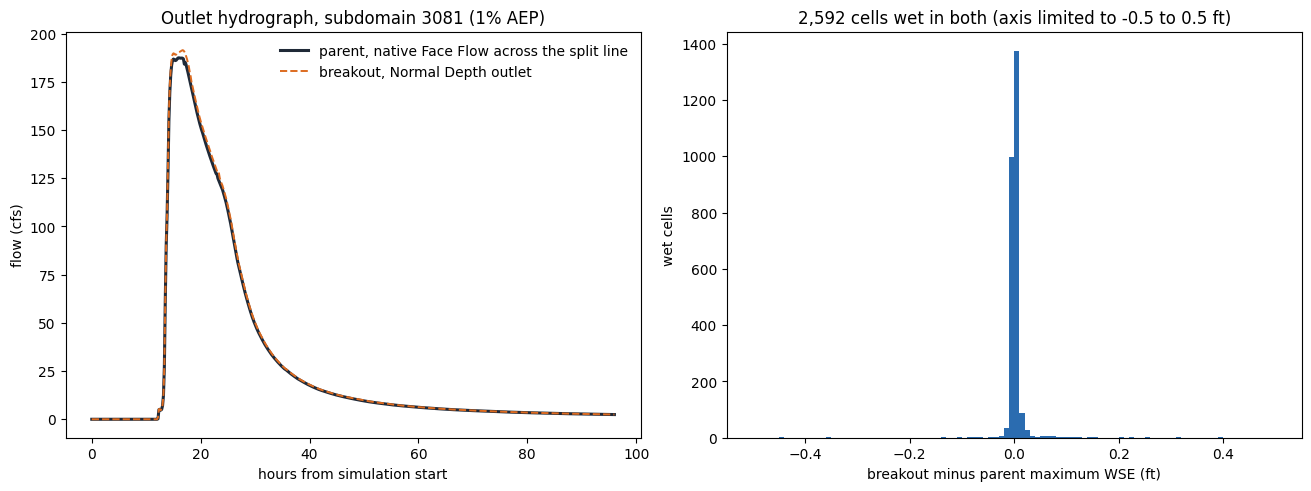

In [11]:
from scipy.spatial import cKDTree

from ras_commander.hdf import HdfResultsMesh
from ras_commander.subdomain._breakouts import _bc_flow
from ras_commander.subdomain._parent import EventReader

child_hdf = Path(runs["plan_hdf_path"].iloc[0])
outlet = search._context["lines"][int(HEADWATER)]
reader = EventReader(parent_1pct, "SLDR_004")
ids, flow = reader.series("Face Flow", outlet["faces"])
col = {int(f): i for i, f in enumerate(ids)}
parent_q = (flow[:, [col[int(f)] for f in outlet["faces"]]] * np.asarray(outlet["signs"])).sum(axis=1)
parent_h = reader.seconds() / 3600
child_h, child_q = _bc_flow(child_hdf, [f"Out_ND_{HEADWATER}"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].plot(parent_h, parent_q, color="#1F2937", linewidth=2.2, label="parent, native Face Flow across the split line")
axes[0].plot(child_h, child_q, color="#DD6B20", linewidth=1.4, linestyle="--", label="breakout, Normal Depth outlet")
axes[0].set(xlabel="hours from simulation start", ylabel="flow (cfs)", title=f"Outlet hydrograph, subdomain {HEADWATER} (1% AEP)")
axes[0].legend(frameon=False)

child_geometry = read_geometry(child_hdf, "SLDR_004")
_, idx = cKDTree(delivered_geometry.cell_center).query(child_geometry.cell_center)
cw = HdfResultsMesh.get_mesh_summary_values(child_hdf, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
pw = HdfResultsMesh.get_mesh_summary_values(parent_1pct, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
c_w = cw.reindex(np.arange(child_geometry.cell_count)).to_numpy()
p_w = pw.reindex(idx).to_numpy()
wet = (((c_w - child_geometry.cell_min_elevation) > 0.1)
       & ((p_w - delivered_geometry.cell_min_elevation[idx]) > 0.1))
axes[1].hist((c_w - p_w)[wet], bins=np.linspace(-0.5, 0.5, 101), color="#2B6CB0")
axes[1].set(xlabel="breakout minus parent maximum WSE (ft)", ylabel="wet cells",
            title=f"{int(wet.sum()):,} cells wet in both (axis limited to -0.5 to 0.5 ft)")
fig.savefig(FIG_DIR / "02_outlet_and_wse.png", dpi=130)
plt.show()

## 9. Where the breakout differs, and why

The summary statistics say the breakout reproduces the parent closely. This
section asks *where* it does not and what hydraulics cause it. A cookie-cut
breakout changes the parent in only two ways:

1. **The subdomain's edge becomes a boundary.**
   - The split line becomes a Normal Depth outlet.
   - Stretches of the HUC perimeter keep Normal Depth, as in the parent.
   - Every other edge, where the subdomain meets a neighbouring catchment
     inside the parent, becomes a closed wall.
2. **The child is run on its own,** held at the parent's time step.

So every difference should trace back to one of these boundaries. Below, each
edge face of the subdomain is classified by kind. The table gives the event
volume the **parent** passed across each kind of edge in the 1% AEP event:
what the breakout's boundaries replace.

In [12]:
import h5py
import shapely
from matplotlib.colors import TwoSlopeNorm
from matplotlib.collections import PolyCollection
from scipy.spatial import cKDTree

from ras_commander.hdf import HdfMesh, HdfResultsMesh
from ras_commander.subdomain import _split_lines as sl
from ras_commander.subdomain._breakouts import _bc_flow
from ras_commander.subdomain._parent import EventReader, face_tables

mesh, lines = search._context["mesh"], search._context["lines"]
OUTLET_BC = f"Out_ND_{HEADWATER}"
outlet_line = lines[int(HEADWATER)]
_, parent_of = cKDTree(delivered_geometry.cell_center).query(child_geometry.cell_center)
inside = np.zeros(mesh.cell_count + 1, bool)
inside[parent_of] = True


def summary(path, ids):
    frame = HdfResultsMesh.get_mesh_summary_values(path, "Maximum Water Surface").set_index("cell_id")
    return (frame["maximum_water_surface"].reindex(ids).to_numpy(),
            pd.to_datetime(frame["maximum_water_surface_time"].reindex(ids)).to_numpy())


child_max, child_time = summary(child_hdf, np.arange(child_geometry.cell_count))
parent_max, parent_time = summary(parent_1pct, parent_of)
cells = pd.DataFrame({
    "parent_cell": parent_of,
    "wse_diff_ft": child_max - parent_max,
    "parent_depth_ft": parent_max - delivered_geometry.cell_min_elevation[parent_of],
    "peak_time_diff_h": (child_time - parent_time).astype("timedelta64[s]").astype(float) / 3600,
    "x": delivered_geometry.cell_center[parent_of, 0], "y": delivered_geometry.cell_center[parent_of, 1],
})

# Classify the subdomain's edge faces: outlet split line, parent (HUC) perimeter, or closed wall.
a, b = mesh.cell_0, mesh.cell_1
real_a, real_b = (a >= 0) & (a < mesh.cell_count), (b >= 0) & (b < mesh.cell_count)
in_a = real_a & inside[np.clip(a, 0, mesh.cell_count)]
in_b = real_b & inside[np.clip(b, 0, mesh.cell_count)]
edge = np.flatnonzero(in_a ^ in_b)
outlet_faces = set(int(f) for f in outlet_line["faces"])
kind = np.where(np.isin(edge, list(outlet_faces)), "outlet",
                np.where(real_a[edge] & real_b[edge], "closed", "HUC perimeter"))
event = search.events[0]
outward = search._context["volume"][event][edge] * np.where(in_a[edge], 1.0, -1.0)
edges = pd.DataFrame({"face": edge, "kind": kind, "parent_volume_out_ft3": outward,
                      "x": mesh.midpoint[edge, 0], "y": mesh.midpoint[edge, 1]})


def seg(faces):
    return shapely.MultiLineString([mesh.point_xy[mesh.points[int(f)]] for f in faces])


points = shapely.points(cells[["x", "y"]].to_numpy())
cells["dist_outlet_ft"] = shapely.distance(points, seg(edges.face[edges.kind == "outlet"]))
cells["dist_closed_ft"] = shapely.distance(points, seg(edges.face[edges.kind == "closed"]))
worst = cells.loc[cells["wse_diff_ft"].abs().idxmax()]
volume_out = edges.groupby("kind")["parent_volume_out_ft3"].agg(
    out=lambda v: v[v > 0].sum(), into=lambda v: -v[v < 0].sum(), faces="size")
print(f"edge faces: {len(edges)}; parent event volume across them (ft3):")
display(volume_out.round(0))
print(f"worst cell: parent {int(worst.parent_cell)}, {worst.wse_diff_ft:+.2f} ft, "
      f"{worst.dist_outlet_ft:.0f} ft from the outlet, {worst.dist_closed_ft:.0f} ft from a closed edge")

edge faces: 242; parent event volume across them (ft3):


,out,into,faces
kind,,,
HUC perimeter,90448.0,-0.0,107
closed,256255.0,82289.0,132
outlet,10013539.0,-0.0,3


worst cell: parent 595349, -1.15 ft, 75 ft from the outlet, 125 ft from a closed edge


**Closed edges are not perfectly closed in the parent.** In a rain-on-grid
model, sheet flow does not respect a terrain-derived divide exactly.

- Across the subdomain's closed edges the parent sent about 256,000 ft³ out and
  took about 82,000 ft³ in. That is 2.6% and 0.8% of the 10.0 million ft³
  leaving through the outlet.
- The breakout turns those faces into walls.
- The search reported this exchange in advance: it labels a subdomain
  `CLOSED_EDGE_LEAKAGE` above 5%, and this one stayed below that in both events.

The table groups cells by distance from the boundaries that changed:

- **Interior (2,194 cells, 85% of the cells):** cells more than 900 ft from
  any closed edge and 600 ft from the outlet match the parent to 0.009 ft at the
  95th percentile.
- **Near closed edges:** the band within 300 ft of a closed edge holds most of
  the cells that differ by more than 0.1 ft.
- **Near the outlet:** the 21 cells within 600 ft of the outlet hold the single
  largest difference.

In [13]:
def zone(row):
    if row.dist_outlet_ft < 600:
        return "within 600 ft of the outlet"
    if row.dist_closed_ft < 300:
        return "within 300 ft of a closed edge"
    if row.dist_closed_ft < 900:
        return "300 to 900 ft from a closed edge"
    return "interior (over 900 ft from closed edges)"


cells["zone"] = cells.apply(zone, axis=1)
absdiff = cells["wse_diff_ft"].abs()
table = cells.assign(abs_diff=absdiff).groupby("zone").agg(
    cells=("abs_diff", "size"),
    p50_ft=("abs_diff", "median"),
    p95_ft=("abs_diff", lambda v: v.quantile(0.95)),
    max_ft=("abs_diff", "max"),
    mean_signed_ft=("wse_diff_ft", "mean"),
    over_0_1_ft=("abs_diff", lambda v: int((v > 0.1).sum())),
)
display(table.round(3))

,cells,p50_ft,p95_ft,max_ft,mean_signed_ft,over_0_1_ft
zone,,,,,,
300 to 900 ft from a closed edge,259,0.001,0.032,0.148,0.005,5
interior (over 900 ft from closed edges),2194,0.000,0.009,0.113,0.001,1
within 300 ft of a closed edge,118,0.006,0.264,0.527,0.016,14
within 600 ft of the outlet,21,0.029,0.105,1.154,-0.038,2


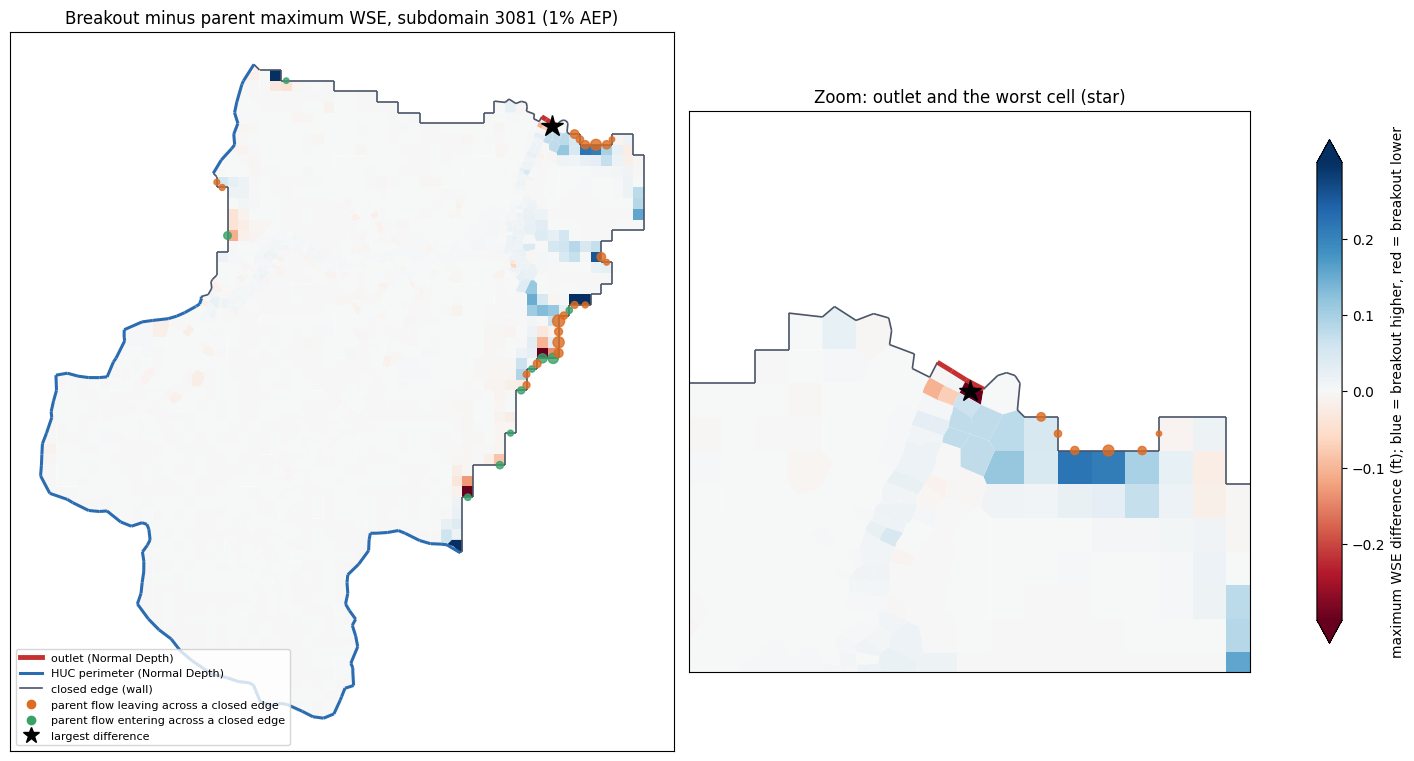

In [14]:
polys = HdfMesh.get_mesh_cell_polygons(child_hdf)
polys = polys[polys["cell_id"] < child_geometry.cell_count].set_index("cell_id").sort_index()
verts = [np.asarray(g.exterior.coords) for g in polys.geometry]
fig, (ax, zoom) = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True,
                               gridspec_kw={"width_ratios": [1.35, 1]})
norm = TwoSlopeNorm(vmin=-0.3, vcenter=0.0, vmax=0.3)
for axis in (ax, zoom):
    pc = PolyCollection(verts, array=cells["wse_diff_ft"].to_numpy(), cmap="RdBu", norm=norm,
                        edgecolors="none")
    axis.add_collection(pc)
    for name, colour, width in (("closed", "#4A5568", 1.2), ("HUC perimeter", "#2B6CB0", 2.2),
                                ("outlet", "#C53030", 3.5)):
        g = seg(edges.face[edges.kind == name])
        for part in g.geoms:
            axis.plot(*np.asarray(part.coords).T, color=colour, linewidth=width, solid_capstyle="butt")
    exch = edges[(edges.kind == "closed") & (edges.parent_volume_out_ft3.abs() > 2000)]
    axis.scatter(exch.x, exch.y, s=np.sqrt(exch.parent_volume_out_ft3.abs()) / 3,
                 c=np.where(exch.parent_volume_out_ft3 > 0, "#DD6B20", "#38A169"), alpha=0.8, zorder=4)
    axis.plot(worst.x, worst.y, marker="*", color="black", markersize=16, zorder=5)
    axis.set_aspect("equal")
    axis.set_xticks([]); axis.set_yticks([])
x0, y0 = worst.x, worst.y
zoom.set_xlim(x0 - 2500, x0 + 2500); zoom.set_ylim(y0 - 2500, y0 + 2500)
ax.autoscale_view()
ax.set_title(f"Breakout minus parent maximum WSE, subdomain {HEADWATER} (1% AEP)")
zoom.set_title("Zoom: outlet and the worst cell (star)")
cbar = fig.colorbar(pc, ax=[ax, zoom], shrink=0.7, extend="both")
cbar.set_label("maximum WSE difference (ft); blue = breakout higher, red = breakout lower")
from matplotlib.lines import Line2D
handles = [Line2D([], [], color="#C53030", lw=3.5, label="outlet (Normal Depth)"),
           Line2D([], [], color="#2B6CB0", lw=2.2, label="HUC perimeter (Normal Depth)"),
           Line2D([], [], color="#4A5568", lw=1.2, label="closed edge (wall)"),
           Line2D([], [], marker="o", ls="", color="#DD6B20", label="parent flow leaving across a closed edge"),
           Line2D([], [], marker="o", ls="", color="#38A169", label="parent flow entering across a closed edge"),
           Line2D([], [], marker="*", ls="", color="black", markersize=12, label="largest difference")]
ax.legend(handles=handles, loc="lower left", fontsize=8, frameon=True)
fig.savefig(FIG_DIR / "03_wse_difference_map.png", dpi=130)
plt.show()

**Reading the map.**

- Blue cells: the breakout's maximum water surface is higher than the parent's.
- Red cells: it is lower.
- Orange dots: the parent sent water *out* across a closed edge.
- Green dots: water came *in* across a closed edge.
- Dot size scales with the square root of the event volume across that face.

The pattern is the hydraulic signature of the walls.

- **Blue next to orange.** Where the parent let water spill over the divide
  into the neighbouring catchment, the breakout's wall holds it back. Cells
  just inside pond a few hundredths to 0.5 ft higher. The longest such stretch
  is the closed edge east of the outlet, where the parent lost the most water.
- **Red next to green.** Where the parent received water from a neighbor, the
  breakout never gets it, and nearby cells peak lower.
- **Interior.** Away from these edges the differences fall to the
  thousandths of a foot. Repeat-run variability was not measured here.

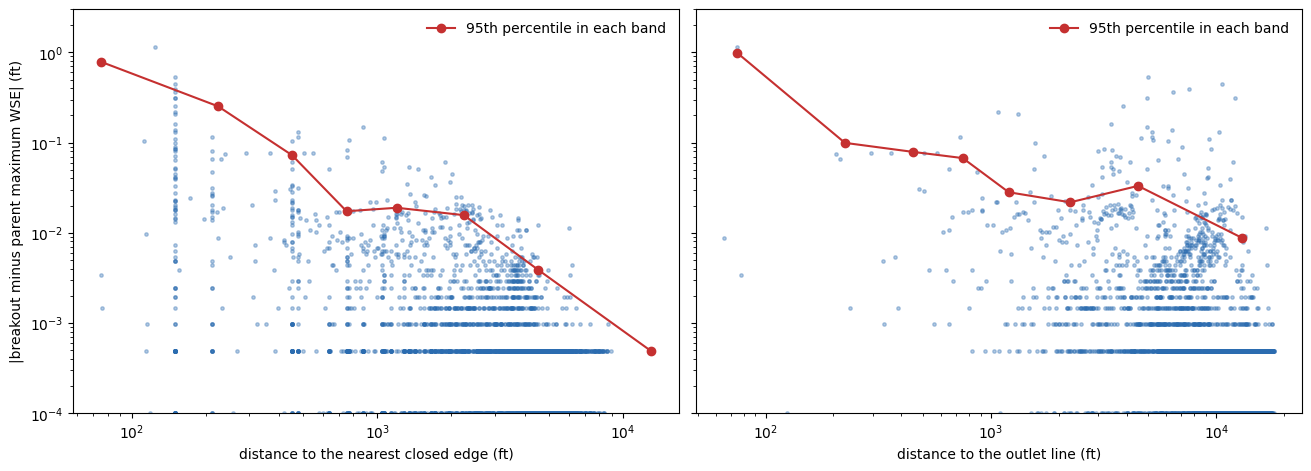

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True, sharey=True)
for axis, col, label in ((axes[0], "dist_closed_ft", "distance to the nearest closed edge (ft)"),
                         (axes[1], "dist_outlet_ft", "distance to the outlet line (ft)")):
    axis.scatter(cells[col], absdiff.clip(lower=1e-4), s=6, color="#2B6CB0", alpha=0.35)
    bins = np.array([0, 150, 300, 600, 900, 1500, 3000, 6000, 20000])
    which = np.digitize(cells[col], bins)
    centers = [(bins[i - 1] + bins[i]) / 2 for i in range(1, len(bins))]
    p95 = [absdiff[which == i].quantile(0.95) if (which == i).any() else np.nan for i in range(1, len(bins))]
    axis.plot(centers, p95, color="#C53030", marker="o", label="95th percentile in each band")
    axis.set(xscale="log", yscale="log", xlabel=label, ylim=(1e-4, 3))
    axis.legend(frameon=False)
axes[0].set_ylabel("|breakout minus parent maximum WSE| (ft)")
fig.savefig(FIG_DIR / "04_error_vs_distance.png", dpi=130)
plt.show()

**Error decays with distance from the boundaries that changed.** The 95th
percentile of the absolute difference falls by more than two orders of
magnitude, from about 0.8 ft at the first band to about 0.0005 ft beyond 6,000 ft
from a closed edge. Against distance to the outlet, the decay is weaker
because closed edges run the length of the subdomain. In this run the
largest differences stay near the boundaries that changed and do not carry into
the interior.

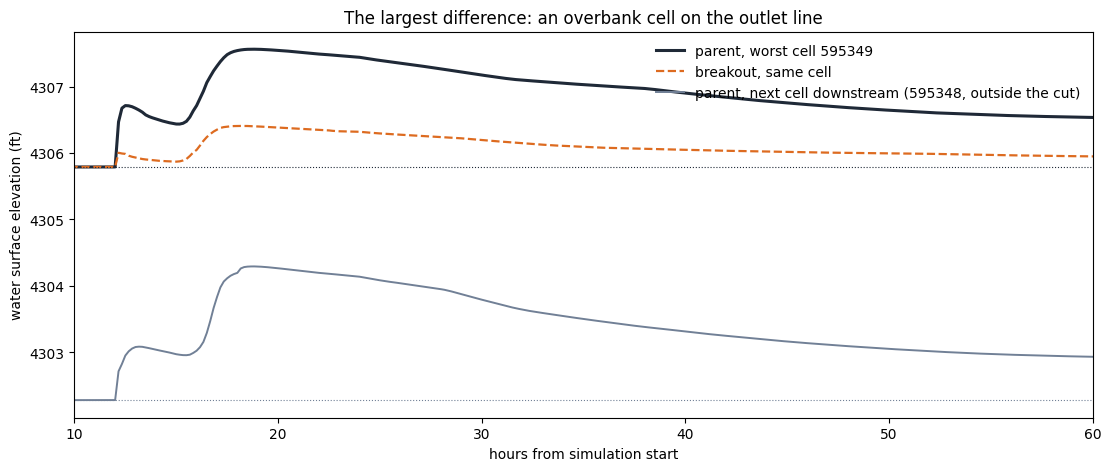

bed elevations: worst cell 4305.79 ft, downstream cell 4302.28 ft, channel stage cell 4297.08 ft


In [16]:
ws = "Results/Unsteady/Output/Output Blocks/Base Output/Unsteady Time Series/2D Flow Areas/SLDR_004/Water Surface"
worst_parent = int(worst.parent_cell)
worst_child = int(np.flatnonzero(parent_of == worst_parent)[0])
downstream_face = next(f for f in outlet_faces if worst_parent in (mesh.cell_0[f], mesh.cell_1[f]))
downstream_cell = int(mesh.cell_1[downstream_face] if mesh.cell_0[downstream_face] == worst_parent
                      else mesh.cell_0[downstream_face])
stage_cell = int(sl.cells_upstream_of(mesh, int(outlet_line["seed"]), outlet_line["downstream"]))
hours = EventReader(parent_1pct, "SLDR_004").seconds() / 3600
with h5py.File(parent_1pct, "r") as f:
    p_worst, p_down = f[ws][:, worst_parent], f[ws][:, downstream_cell]
with h5py.File(child_hdf, "r") as f:
    c_worst = f[ws][:, worst_child]
bed = delivered_geometry.cell_min_elevation
fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
ax.plot(hours, p_worst, color="#1F2937", lw=2.2, label=f"parent, worst cell {worst_parent}")
ax.plot(hours, c_worst, color="#DD6B20", lw=1.6, ls="--", label="breakout, same cell")
ax.plot(hours, p_down, color="#718096", lw=1.4, label=f"parent, next cell downstream ({downstream_cell}, outside the cut)")
for cell, colour in ((worst_parent, "#1F2937"), (downstream_cell, "#718096")):
    ax.axhline(bed[cell], color=colour, lw=0.8, ls=":")
ax.set(xlim=(10, 60), xlabel="hours from simulation start", ylabel="water surface elevation (ft)",
       title="The largest difference: an overbank cell on the outlet line")
ax.legend(frameon=False, loc="upper right")
fig.savefig(FIG_DIR / "05_worst_cell_series.png", dpi=130)
plt.show()
print(f"bed elevations: worst cell {bed[worst_parent]:.2f} ft, downstream cell {bed[downstream_cell]:.2f} ft, "
      f"channel stage cell {bed[stage_cell]:.2f} ft")

**The largest difference is a local outfall control, not a misplaced split
line.** The worst cell lies on the outlet line itself, 75 ft from it and 125 ft
from a closed edge.

- **Where it sits.** Two of the outlet line's three faces cross the channel at
  the bed, near 4,297 ft. The third face crosses an overbank cell whose bed is
  4,305.8 ft, 8.7 ft higher.
- **The parent.** That cell drains over its downstream face as a free outfall:
  the next cell downstream, outside the cut, stays more than 3 ft lower
  throughout. Flow over the face is controlled by the face's own sill, and the
  cell ponds 0.7 to 1.75 ft deep for days.
- **The breakout.** That face is part of the Normal Depth line, so HEC-RAS
  assigns its outflow from the outlet friction slope, 0.006695 (the mean of the
  slopes fitted in the two events).
  The overbank cell therefore drains more freely, and its maximum water surface
  is 1.15 ft lower.

The channel itself is unaffected, as the rating below shows. A placement that
ends the outlet line at the channel banks, leaving the perched overbank face
closed, should remove this; that refinement has not been tested here. It concerns
BC line placement, not the split-line search.

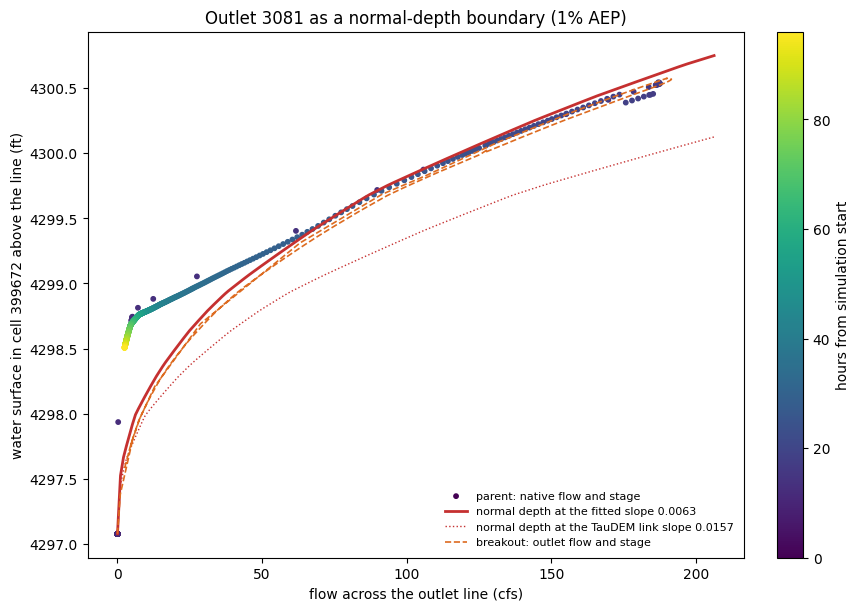

,event,walk_step,best_slope,rmse_ft,peak_error_ft,loop_ft,reverse_fraction,outflow_share
14883,1pct,4,0.0063,0.1747,0.0783,0.1142,0.0,0.9263
42071,0_2pct,4,0.0071,0.1031,0.3216,0.1577,0.0,0.9184


In [17]:
reader = EventReader(parent_1pct, "SLDR_004")
ids, flow = reader.series("Face Flow", outlet_line["faces"])
col = {int(f): i for i, f in enumerate(ids)}
oriented = flow[:, [col[int(f)] for f in outlet_line["faces"]]] * np.asarray(outlet_line["signs"])
parent_q = oriented.sum(axis=1)
with h5py.File(parent_1pct, "r") as f:
    parent_stage = f[ws][:, stage_cell]
child_stage_cell = int(np.flatnonzero(parent_of == stage_cell)[0])
with h5py.File(child_hdf, "r") as f:
    child_stage = f[ws][:, child_stage_cell]
child_h, child_q = _bc_flow(child_hdf, [OUTLET_BC])
child_q = np.interp(hours, child_h, child_q)
tables = face_tables(parent_1pct, "SLDR_004", outlet_line["faces"])
criteria = search.criteria
grid, k = sl.stage_grid(float(bed[stage_cell]), lambda z: sl.conveyance(tables, outlet_line["faces"], z, mesh.length),
                        step=criteria.stage_step_ft, span=criteria.stage_span_ft)
row = search.split_lines.set_index("split_line_id").loc[int(HEADWATER)]
slope = float(row[f"best_slope_{event}"])
q_grid = np.linspace(0, parent_q.max() * 1.1, 200)
nd_stage = sl.normal_depth_stage(q_grid, grid, k, slope)
link_stage = sl.normal_depth_stage(q_grid, grid, k, float(row["link_slope"]))
fig, ax = plt.subplots(figsize=(8.5, 6), constrained_layout=True)
sc = ax.scatter(parent_q, parent_stage, c=hours, cmap="viridis", s=10, label="parent: native flow and stage")
ax.plot(q_grid, nd_stage, color="#C53030", lw=2, label=f"normal depth at the fitted slope {slope:.4f}")
ax.plot(q_grid, link_stage, color="#C53030", lw=1, ls=":", label=f"normal depth at the TauDEM link slope {row['link_slope']:.4f}")
ax.plot(child_q, child_stage, color="#DD6B20", lw=1.2, ls="--", label="breakout: outlet flow and stage")
ax.set(xlabel="flow across the outlet line (cfs)", ylabel=f"water surface in cell {stage_cell} above the line (ft)",
       title=f"Outlet {HEADWATER} as a normal-depth boundary (1% AEP)")
fig.colorbar(sc, ax=ax, label="hours from simulation start")
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.savefig(FIG_DIR / "06_outlet_rating.png", dpi=130)
plt.show()
fit = search.candidates[(search.candidates.split_line_id == int(HEADWATER)) & search.candidates.chosen]
display(fit[["event", "walk_step", "best_slope", "rmse_ft", "peak_error_ft", "loop_ft", "reverse_fraction",
             "outflow_share"]].round(4))

**The outlet as a normal-depth boundary.** The dots are the parent's own native
flow across the split line, plotted against the water surface in the cell above
it and colored by time. The red curve is the normal-depth rating the search
fitted from the face property tables at the best single slope; the orange
dashes are the breakout.

- **The fit holds where it matters.** Above roughly 50 cfs, which covers the
  rising limb, the peak and the main recession, the parent's stage-discharge
  pairs lie on the normal-depth curve. The search accepted this line because
  that fit held in **both** events: the table shows RMSE 0.17 ft (1%) and
  0.10 ft (0.2%), no reverse flow, and 92% to 93% of the contributing area's
  outflow crossing the line. The breakout's outlet follows the same curve;
  its peak is 2.1% higher and 40 minutes later than the parent's.
- **The fitted slope, not the terrain slope.** The TauDEM link slope (dotted)
  would put the peak stage about 0.4 ft too low. The 100 ft DEM averages the
  channel bed slope over a reach steeper than the hydraulic control at this
  section.
- **What normal depth cannot represent.** On the long low-flow tail, the
  parent's stage hangs 0.5 to 0.8 ft above normal depth: downstream storage
  drains slowly and holds the section up. A normal-depth boundary cannot
  reproduce that. Because it happens after the peak, it does not affect maximum
  water surfaces. It would matter for a long-duration or low-flow analysis, and
  it is the reason for the guidance not to use normal-depth breakouts in flat,
  backwater-controlled reaches.

## 10. Walls or closed-edge outflow: both runs compared

Section 9 traced most of the breakout's error to its closed edges, which are
walls in the breakout but slightly open in the parent. `plan_breakouts` offers
one alternative: `closed_edge_outflow=True` puts Normal Depth outflow lines
along those edges.

- **Slope:** 0.00033, chosen by the project engineer as a conservative minimum
  that lets water escape; no slope-sensitivity study is shown here.
- **Spacing:** each line stops 2 cell faces short of the outlet and perimeter
  lines, so HEC-RAS never assigns two lines to one face.

The same headwater is authored, validated and run again with that option in
HEC-RAS 6.4.1, then compared with the parent alongside the walled run.

In [18]:
BREAKOUT_OPEN_DIR = WORK_ROOT / "06_breakout_closed_edge_outflow"
open_plan = RasSubdomain.plan_breakouts(partition, "01", ras_object=parent, subdomain_ids=[HEADWATER],
                                        closed_edge_outflow=True)
display(open_plan.checks)
assert open_plan.is_ready
display(pd.DataFrame([{k: b[k] for k in ("role", "name", "bc_type", "friction_slope")}
                      for b in open_plan.breakouts[0].bc_lines]))
t0 = time.time()
open_set = RasSubdomain.apply_breakouts(open_plan, BREAKOUT_OPEN_DIR, overwrite_dest=True)
print(f"authored in {(time.time() - t0) / 60:.1f} min")
open_checks = RasSubdomain.validate_breakouts(open_set)
display(open_checks)
assert not open_checks["blocking"].any()
open_runs = RasSubdomain.compute_subdomains(open_set, max_workers=1, num_cores=NUM_CORES)
assert open_runs["success"].all()
open_hdf = Path(open_runs["plan_hdf_path"].iloc[0])
open_comparison = RasSubdomain.compare_to_parent(open_set, parent_1pct)
display(pd.concat({"walls (default)": comparison.set_index("subdomain_id").T,
                   "closed-edge outflow": open_comparison.set_index("subdomain_id").T}, axis=1))

2026-10-25 20:09:30 - ras_commander.RasBreakout2D - INFO - 2D breakout preflight sd_3081: ready=True, features=4102


,subdomain_id,check,passed,blocking,detail
0,*,parent_geometry_matches_search,True,False,SLDR_004.g02.hdf matches the searched mesh
1,3081,single_polygon_boundary,True,False,child boundary is Polygon with 0 holes
2,3081,has_outflow_boundary,True,False,1 outlet and 2 perimeter and 3 closed-edge out...
3,3081,breakout_preflight,True,False,ready


,role,name,bc_type,friction_slope
0,outlet,Out_ND_3081,Normal Depth,0.006695
1,perimeter,Edge_ND_1,Normal Depth,0.010000
2,perimeter,Edge_ND_2,Normal Depth,0.010000
3,closed_edge_outflow,Edge_Out_1,Normal Depth,0.000330
4,closed_edge_outflow,Edge_Out_2,Normal Depth,0.000330
5,closed_edge_outflow,Edge_Out_3,Normal Depth,0.000330


2026-10-25 20:09:40 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-25 20:09:40 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


...

2026-10-25 20:15:53 - ras_commander.RasCmdr - INFO - Plan 08 in worker 1: Successful


2026-10-25 20:15:53 - ras_commander.RasCmdr - INFO - Consolidating worker artifacts back to original project folder: Input


2026-10-25 20:15:56 - ras_commander.RasCmdr - INFO - Consolidated 3 worker artifact(s) to Input


2026-10-25 20:15:56 - ras_commander.RasCmdr - INFO - Execution results: 1/1 plan(s) successful


,walls (default),closed-edge outflow
subdomain_id,3081,3081
status,compared,compared
cells,2592,2592
cells_matched_to_parent,2592,2592
wet_cells_compared,2592,2592
wse_diff_p50_ft,0.000488,0.000488
wse_diff_p95_ft,0.01709,0.031738
wse_diff_p99_ft,0.082739,0.421821
wse_diff_max_ft,1.154297,2.975098
wse_diff_mean_ft,0.001479,-0.017229


In [19]:
open_geometry = read_geometry(open_hdf, "SLDR_004")
_, open_parent_of = cKDTree(delivered_geometry.cell_center).query(open_geometry.cell_center)
open_max, _ = summary(open_hdf, np.arange(open_geometry.cell_count))
open_diff = pd.Series(open_max, index=open_parent_of) - pd.Series(parent_max, index=parent_of).reindex(open_parent_of).to_numpy()
cells["wse_diff_open_ft"] = open_diff.reindex(cells["parent_cell"]).to_numpy()
both = cells.assign(walls=cells["wse_diff_ft"].abs(), outflow=cells["wse_diff_open_ft"].abs())
zone_table = both.groupby("zone").agg(
    cells=("walls", "size"),
    walls_p95_ft=("walls", lambda v: v.quantile(0.95)),
    outflow_p95_ft=("outflow", lambda v: v.quantile(0.95)),
    walls_max_ft=("walls", "max"),
    outflow_max_ft=("outflow", "max"),
    walls_mean_signed_ft=("wse_diff_ft", "mean"),
    outflow_mean_signed_ft=("wse_diff_open_ft", "mean"),
)
display(zone_table.round(3))


def bc_volumes(path):
    ds = HdfResultsMesh.get_boundary_conditions_timeseries(path)
    seconds = ds["time"].values.astype("datetime64[s]").astype(float)
    return {str(n): float(np.trapezoid(np.abs(ds["flow"].sel(bc_name=n).values), seconds))
            for n in ds["bc_name"].values.tolist()}


outlet_parent = float(edges.loc[edges.kind == "outlet", "parent_volume_out_ft3"].sum())
closed_parent = edges.loc[edges.kind == "closed", "parent_volume_out_ft3"]
budget = pd.DataFrame({
    "walls (default)": pd.Series(bc_volumes(child_hdf)),
    "closed-edge outflow": pd.Series(bc_volumes(open_hdf)),
}).fillna(0.0)
budget.loc["parent: out across closed edges"] = [closed_parent[closed_parent > 0].sum()] * 2
budget.loc["parent: into the subdomain across closed edges"] = [-closed_parent[closed_parent < 0].sum()] * 2
display((budget / 1e3).round(1).rename(columns=lambda c: f"{c} (1,000 ft3)"))
display((100 * budget / outlet_parent).round(2).rename(columns=lambda c: f"{c} (% of parent outlet volume)"))

,cells,walls_p95_ft,outflow_p95_ft,walls_max_ft,outflow_max_ft,walls_mean_signed_ft,outflow_mean_signed_ft
zone,,,,,,,
300 to 900 ft from a closed edge,259,0.032,0.108,0.148,1.327,0.005,-0.022
interior (over 900 ft from closed edges),2194,0.009,0.011,0.113,0.205,0.001,-0.002
within 300 ft of a closed edge,118,0.264,1.229,0.527,2.975,0.016,-0.276
within 600 ft of the outlet,21,0.105,0.220,1.154,1.349,-0.038,-0.114


,"walls (default) (1,000 ft3)","closed-edge outflow (1,000 ft3)"
Edge_ND_1,78.4,78.4
Edge_ND_2,12.6,12.6
Edge_Out_1,0.0,374.1
Edge_Out_2,0.0,11.4
Edge_Out_3,0.0,24.9
Out_ND_3081,10217.3,9832.4
parent: out across closed edges,256.3,256.3
parent: into the subdomain across closed edges,82.3,82.3


,walls (default) (% of parent outlet volume),closed-edge outflow (% of parent outlet volume)
Edge_ND_1,0.78,0.78
Edge_ND_2,0.13,0.13
Edge_Out_1,0.00,3.74
Edge_Out_2,0.00,0.11
Edge_Out_3,0.00,0.25
Out_ND_3081,102.03,98.19
parent: out across closed edges,2.56,2.56
parent: into the subdomain across closed edges,0.82,0.82


**Where the water goes.** The second table expresses each boundary's event
volume as a share of what the parent passed through the same outlet faces.

- **Parent:** across the closed edges it sent 2.6% out and took 0.8% in, a
  net 1.7% out.
- **Walls (default):** they release nothing across the divide. That water stays
  in the subdomain and leaves through the outlet, which passes 102.0% of the
  parent's volume.
- **Closed-edge outflow:** the three lines pass 4.1% of the outlet volume,
  almost all through the longest line. That is more than the parent's gross
  outflow across the same edges and well over twice its net. The outlet passes
  98.2%.

The zone table shows where that matters. Within 300 ft of a closed edge, the
95th-percentile difference grows from 0.26 ft to 1.23 ft. The mean changes sign
from +0.016 ft to −0.28 ft. The interior, more than 900 ft from closed edges, is
nearly unchanged (0.009 ft and 0.011 ft).

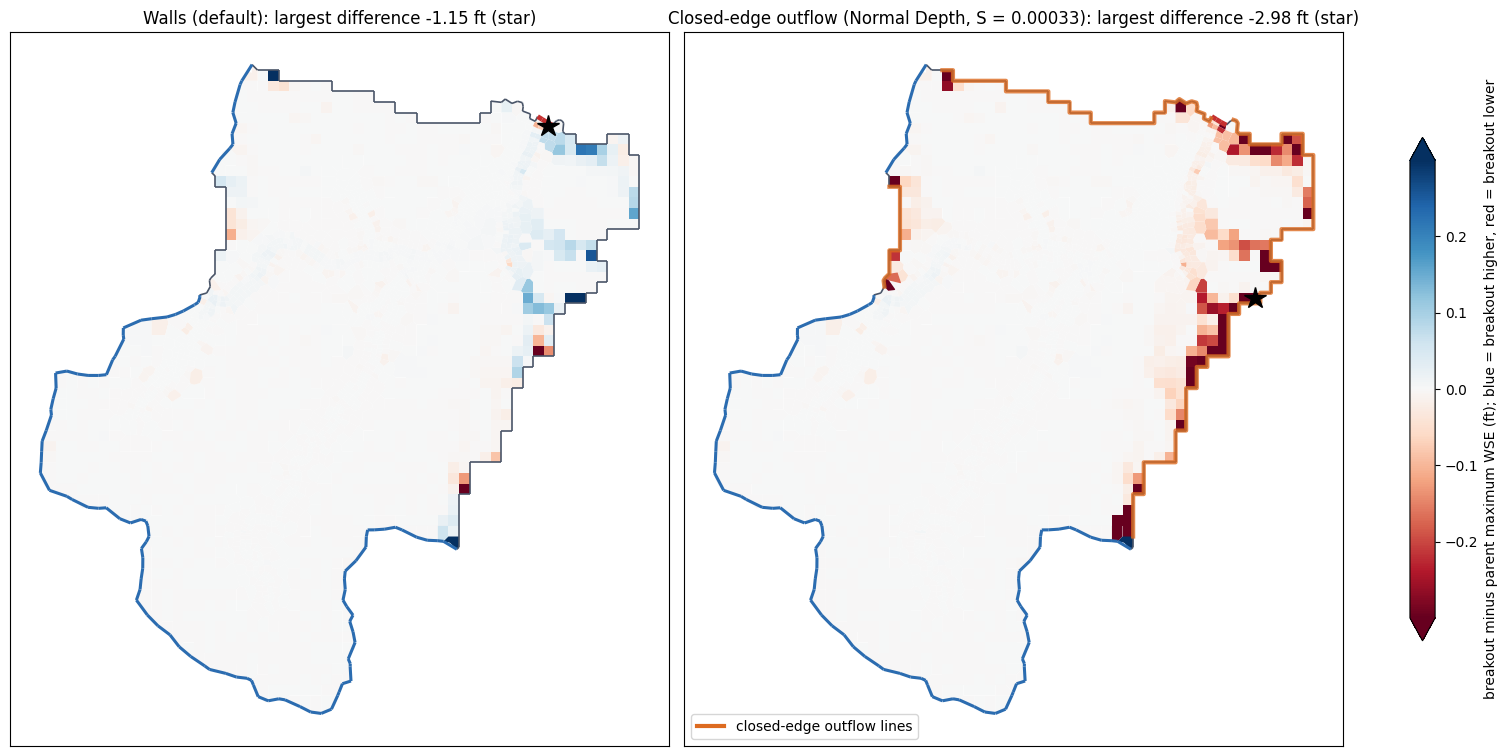

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True)
for axis, column, title in ((axes[0], "wse_diff_ft", "Walls (default)"),
                            (axes[1], "wse_diff_open_ft", "Closed-edge outflow (Normal Depth, S = 0.00033)")):
    pc = PolyCollection(verts, array=cells[column].to_numpy(), cmap="RdBu", norm=norm, edgecolors="none")
    axis.add_collection(pc)
    for name, colour, width in (("closed", "#4A5568", 1.2), ("HUC perimeter", "#2B6CB0", 2.2),
                                ("outlet", "#C53030", 3.5)):
        for part in seg(edges.face[edges.kind == name]).geoms:
            axis.plot(*np.asarray(part.coords).T, color=colour, linewidth=width, solid_capstyle="butt")
    k = cells[column].abs().idxmax()
    axis.plot(cells.at[k, "x"], cells.at[k, "y"], marker="*", color="black", markersize=16, zorder=5)
    axis.set_aspect("equal"); axis.autoscale_view(); axis.set_xticks([]); axis.set_yticks([])
    axis.set_title(f"{title}: largest difference {cells.at[k, column]:+.2f} ft (star)")
for b in open_plan.breakouts[0].bc_lines:
    if b["role"] == "closed_edge_outflow":
        axes[1].plot(*np.asarray(b["coordinates"])[:, :2].T, color="#DD6B20", linewidth=3, alpha=0.8)
cbar = fig.colorbar(pc, ax=list(axes), shrink=0.7, extend="both")
cbar.set_label("breakout minus parent maximum WSE (ft); blue = breakout higher, red = breakout lower")
axes[1].plot([], [], color="#DD6B20", lw=3, label="closed-edge outflow lines")
axes[1].legend(loc="lower left", frameon=True)
fig.savefig(FIG_DIR / "07_walls_vs_closed_edge_outflow.png", dpi=130)
plt.show()

**The two error patterns.**

- **Walls (left):** small differences of both signs at a few points along the
  divide. The breakout is higher just inside where the parent spilled out, and
  lower where it took water in.
- **Closed-edge outflow (right):** a continuous red band along every outflow
  line. The breakout is lower all along the divide.

The largest difference moves from the perched overbank cell at the outlet
(−1.15 ft) to a pond against the divide (−2.98 ft). In the parent that pond is
held up by the terrain and by water standing on the far side of the divide. A
normal-depth edge sees neither, so it drains the pond toward normal depth even at
the minimum slope.

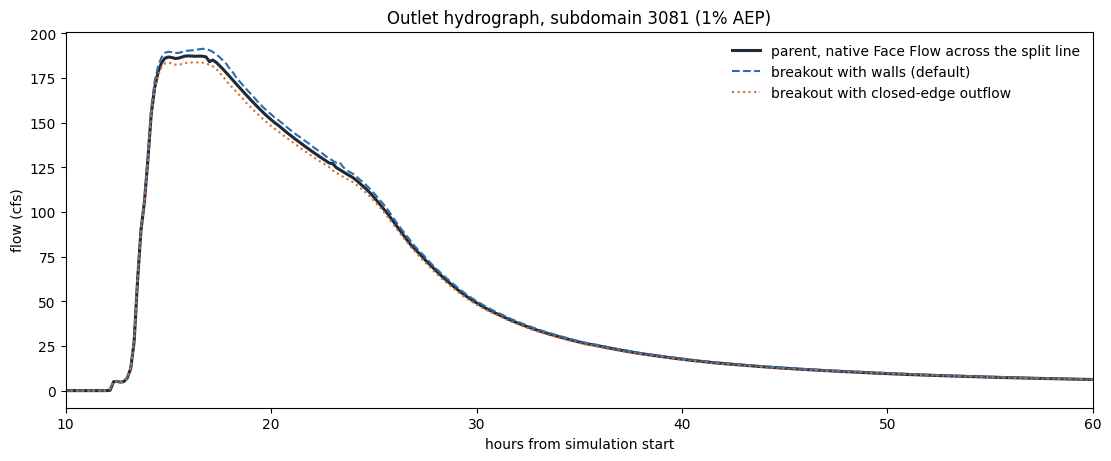

In [21]:
open_h, open_q = _bc_flow(open_hdf, [OUTLET_BC])
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ax.plot(hours, parent_q, color="#1F2937", lw=2.2, label="parent, native Face Flow across the split line")
ax.plot(hours, child_q, color="#2B6CB0", lw=1.5, ls="--", label="breakout with walls (default)")
ax.plot(open_h, open_q, color="#DD6B20", lw=1.5, ls=":", label="breakout with closed-edge outflow")
ax.set(xlim=(10, 60), xlabel="hours from simulation start", ylabel="flow (cfs)", title=f"Outlet hydrograph, subdomain {HEADWATER} (1% AEP)")
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "08_outlet_both_variants.png", dpi=130)
plt.show()

**The outlet barely separates the two.** The parent's hydrograph lies between
them: the walled breakout's peak and volume are about 2% high and the outflow
breakout's about 2% low, and both have NSE 0.9994. The WSE maps near the edges
separate the variants far more clearly.

### Limitations, and the choice of walls

Every breakout replaces part of the parent's hydraulics with boundary
conditions. These are the limits of each choice made here.

**Limitations of both variants**

- **Outlet.** The outlet is a normal-depth control. It holds where the parent's
  own stage-discharge follows normal depth (section 9). It cannot represent
  backwater, or the slow low-flow tail where downstream storage holds the stage
  up, so the method is not suited to flat, backwater-controlled reaches.
- **Inflow from neighbours.** Water the parent received across the divide (0.8%
  of the outlet volume here) is not represented, so cells next to those inflow
  points peak lower.
- **Outlet line placement.** An outlet line that crosses a perched overbank
  face drains that cell more freely than the parent; this is the −1.15 ft cell.

**Walls (default)**

- They stop the parent's outflow across the divide (2.6% gross, 1.7% net), so
  that water leaves at the outlet instead (+2.0% volume).
- Cells just inside the parent's spill points peak higher, by up to 0.53 ft.

**Closed-edge outflow**

- It is one-way and sees no water on the far side of the divide, so it
  over-releases: 4.1% of the outlet volume against the parent's net 1.7%.
- It drains depression storage held against the divide (−2.98 ft).
- It lowers maximum water surfaces along the whole closed edge.

**Why walls are the best answer for this subdomain**

1. **Closer agreement.** Maximum WSE agrees better wherever the two differ: 95th
   percentile 0.017 ft against 0.032 ft overall, and 0.26 ft against 1.23 ft
   within 300 ft of a closed edge.
2. **Local, predictable differences.** Wall differences are confined to the parent's spill
   and intake points, which can be located in advance from the parent's
   closed-edge exchange (section 9, orange and green dots).
3. **More area within tolerance.** 98.9% of the subdomain area agrees within
   0.1 ft, against 96.3%.
4. **Direction.** Where the parent spilled water out, walls hold it and raise
   the water surface locally; closed-edge outflow lowers it all along the
   divide. For flood-risk mapping, a local overstatement is the conservative
   side, though the implication depends on the project's decision criteria.

Closed-edge outflow remains available for subdomains where the parent shows
mostly one-way spill across the divide with no ponded storage against it.
Where substantial flow passes between basins in both directions, neither
boundary is right: extend the breakout to include both basins.

## 11. Where the breakout can be used: the 0.1 ft envelope

A breakout is fit for project-level work where it reproduces the parent within
the tolerance the analysis needs. This example uses 0.1 ft on the maximum WSE. In
the project engineer's judgment that is adequate for most project-level analysis
for regulatory purposes; suitability for a given analysis still rests on its
criteria and engineering review. The map shows which cells of the walled breakout meet it. The dark outline marks a
simple setback rule: every cell farther than the given distance from both a
closed edge and the outlet meets the tolerance.

walls: 2,570 of 2,592 cells (99.2%) and 98.9% of the area agree within 0.1 ft
closed-edge outflow: 2,521 cells (97.3%) and 96.3% of the area
every cell more than 1,100 ft from a closed edge and from the outlet is within 0.1 ft: 77.8% of the subdomain


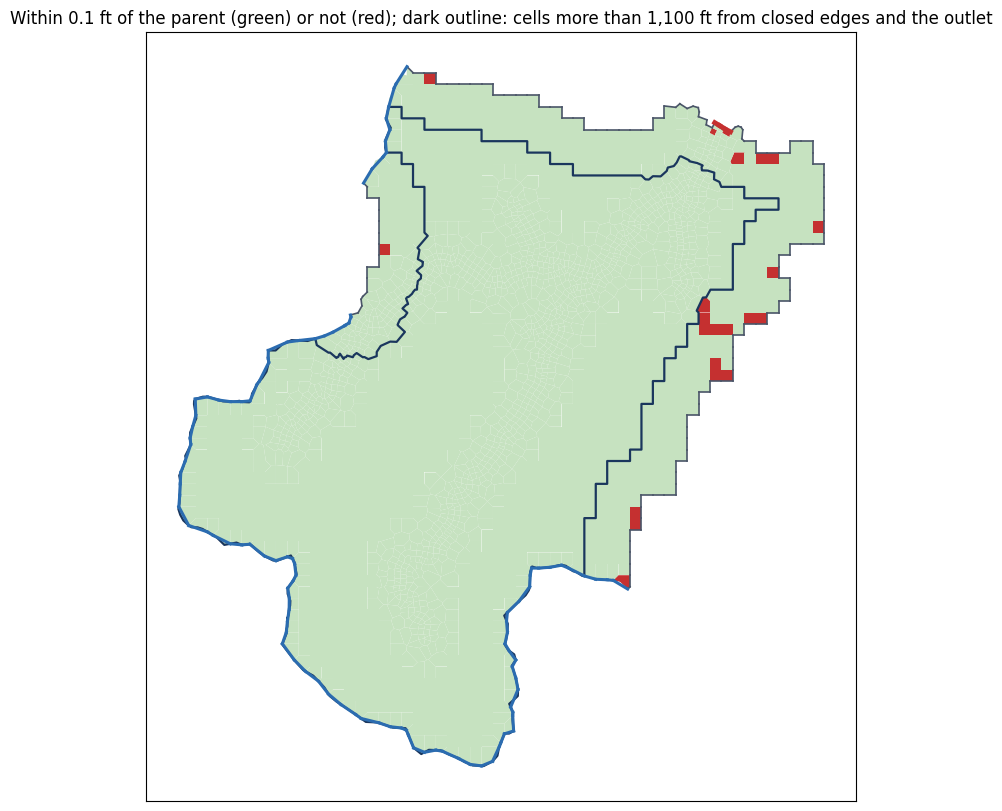

In [22]:
TOLERANCE_FT = 0.1
cell_area = polys.geometry.area.to_numpy()
within = cells["wse_diff_ft"].abs().to_numpy() <= TOLERANCE_FT
print(f"walls: {within.sum():,} of {len(cells):,} cells ({100 * within.mean():.1f}%) and "
      f"{100 * cell_area[within].sum() / cell_area.sum():.1f}% of the area agree within {TOLERANCE_FT} ft")
open_within = cells["wse_diff_open_ft"].abs().to_numpy() <= TOLERANCE_FT
print(f"closed-edge outflow: {open_within.sum():,} cells ({100 * open_within.mean():.1f}%) and "
      f"{100 * cell_area[open_within].sum() / cell_area.sum():.1f}% of the area")
# The smallest setback from closed edges and the outlet beyond which every cell is within tolerance.
setback = cells[["dist_closed_ft", "dist_outlet_ft"]].min(axis=1).to_numpy()
outside = ~within
SETBACK_FT = float(np.ceil(setback[outside].max() / 50.0) * 50.0) if outside.any() else 0.0
inside_setback = setback > SETBACK_FT
print(f"every cell more than {SETBACK_FT:,.0f} ft from a closed edge and from the outlet is within "
      f"{TOLERANCE_FT} ft: {100 * cell_area[inside_setback].sum() / cell_area.sum():.1f}% of the subdomain")
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
colours = np.where(within, "#C6E2C0", "#C53030")
ax.add_collection(PolyCollection(verts, facecolors=colours, edgecolors="none"))
envelope = shapely.union_all([g for g, keep in zip(polys.geometry, inside_setback) if keep])
for part in getattr(envelope, "geoms", [envelope]):
    ax.plot(*np.asarray(part.exterior.coords).T, color="#1A365D", lw=1.6)
for name, colour, width in (("closed", "#4A5568", 1.2), ("HUC perimeter", "#2B6CB0", 2.2), ("outlet", "#C53030", 3.5)):
    for part in seg(edges.face[edges.kind == name]).geoms:
        ax.plot(*np.asarray(part.coords).T, color=colour, linewidth=width)
ax.set_aspect("equal"); ax.autoscale_view(); ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"Within {TOLERANCE_FT} ft of the parent (green) or not (red); dark outline: "
             f"cells more than {SETBACK_FT:,.0f} ft from closed edges and the outlet")
fig.savefig(FIG_DIR / "09_tolerance_envelope.png", dpi=130)
plt.show()

**The envelope is most of the subdomain.**

- **Cells within tolerance:** 2,570 of 2,592 cells, 98.9% of the area, are within
  0.1 ft of the parent. The 22 that are not lie at the parent's spill and intake
  points on the divide and at the outlet.
- **Setback rule:** every cell more than 1,100 ft from a closed edge and from the
  outlet is within tolerance; that is 77.8% of the subdomain.
- **What it means for a project:** a project whose area of interest lies inside
  the setback, or in the green cells outside it, can be analyzed with this
  breakout instead of the parent.

**Comparing alternatives.** A project compares alternatives with each other: an
alternative breakout against the existing-conditions breakout, both run with the
same boundaries. The breakout's boundary effects are then common to both runs
and are expected to largely cancel; this notebook does not test that. The
envelope sets where the existing-conditions breakout
itself can stand in for the parent.

## 12. A second, larger subdomain

The headwater is small, and in the worse event the volume it exchanges (in and
out) across its edges other than the outlet is 4.4% of its outlet volume. The second subdomain tests the method where the divide
matters less and the subdomain is larger. The rule:

- 15 to 50 sq mi;
- none of the labels the cut refuses, and no `CLOSED_EDGE_LEAKAGE`;
- the lowest closed-edge exchange in the worse event.

It may lie anywhere in the network. A subdomain with an upstream neighbour gets
an inflow line forced with the parent's own flow across that split line, from
the parent run of the same plan (the 1% AEP here).

In [23]:
blocking = {"HOLES", "MULTIPART", "STRUCTURE_ON_SPLIT_LINE", "CLOSED_EDGE_LEAKAGE"}
larger = subdomains[(subdomains["subdomain_id"] != partition.remainder_id)
                    & subdomains["labels"].apply(lambda labels: not blocking & set(labels))
                    & subdomains["area_sqmi"].between(15, 50)].copy()
larger["worst_leak"] = larger[leak].max(axis=1)
larger = larger.sort_values("worst_leak")
display(larger[["subdomain_id", "tier", "role", "upstream_subdomain_ids", "cell_count", "area_sqmi", *leak]].head())
SECOND = larger["subdomain_id"].iloc[0]
second_row = larger.iloc[0]
print(f"second subdomain {SECOND}: tier {second_row['tier']}, {int(second_row['cell_count']):,} cells, "
      f"{second_row['area_sqmi']:.1f} sq mi, {len(second_row['upstream_subdomain_ids'])} upstream subdomain(s); "
      f"closed-edge exchange {100 * second_row['worst_leak']:.1f}% of outlet volume in the worse event")

,subdomain_id,tier,role,upstream_subdomain_ids,cell_count,area_sqmi,leak_fraction_1pct,leak_fraction_0_2pct
91,2402,19,downstream,[2386],9418,18.918377,0.002987,0.024469
65,2054,1,headwater,[],21094,42.079953,0.030064,0.032903
39,3565,1,headwater,[],9798,20.743467,0.038800,0.041851
34,3717,1,headwater,[],8706,17.986809,0.040534,0.048359


second subdomain 2402: tier 19, 9,418 cells, 18.9 sq mi, 1 upstream subdomain(s); closed-edge exchange 2.4% of outlet volume in the worse event


It is authored, validated, run on 2 cores and compared with the parent exactly
as the headwater was, with walls on its closed edges.

In [24]:
second_plan = RasSubdomain.plan_breakouts(partition, "01", ras_object=parent, subdomain_ids=[SECOND])
display(second_plan.checks)
assert second_plan.is_ready
display(pd.DataFrame([{k: b[k] for k in ("role", "name", "bc_type", "friction_slope")}
                      for b in second_plan.breakouts[0].bc_lines]))
t0 = time.time()
second_set = RasSubdomain.apply_breakouts(second_plan, WORK_ROOT / "07_breakout_second", overwrite_dest=True)
print(f"authored in {(time.time() - t0) / 60:.1f} min")
second_checks = RasSubdomain.validate_breakouts(second_set)
display(second_checks)
assert not second_checks["blocking"].any()
second_runs = RasSubdomain.compute_subdomains(second_set, max_workers=1, num_cores=NUM_CORES)
assert second_runs["success"].all()
second_hdf = Path(second_runs["plan_hdf_path"].iloc[0])
second_comparison = RasSubdomain.compare_to_parent(second_set, parent_1pct)
display(pd.concat({f"headwater {HEADWATER}": comparison.set_index("subdomain_id").T,
                   f"second {SECOND}": second_comparison.set_index("subdomain_id").T}, axis=1))

2026-10-25 20:17:29 - ras_commander.RasBreakout2D - INFO - 2D breakout preflight sd_2402: ready=True, features=4102


,subdomain_id,check,passed,blocking,detail
0,*,parent_geometry_matches_search,True,False,SLDR_004.g02.hdf matches the searched mesh
1,*,inflow_event_matches_plan,True,False,inflow hydrographs from search event 1pct
2,2402,single_polygon_boundary,True,False,child boundary is Polygon with 0 holes
3,2402,has_outflow_boundary,True,False,1 outlet and 5 perimeter and 0 closed-edge out...
4,2402,breakout_preflight,True,False,ready


,role,name,bc_type,friction_slope
0,outlet,Out_ND_2402,Normal Depth,0.006695
1,inflow,In_2386,Flow Hydrograph,0.010000
2,perimeter,Edge_ND_1,Normal Depth,0.010000
3,perimeter,Edge_ND_2,Normal Depth,0.010000
4,perimeter,Edge_ND_3,Normal Depth,0.010000
5,perimeter,Edge_ND_4,Normal Depth,0.010000
6,perimeter,Edge_ND_5,Normal Depth,0.010000


2026-10-25 20:17:39 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-25 20:17:39 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


...

2026-10-25 20:26:21 - ras_commander.RasCmdr - INFO - Plan 08 in worker 1: Successful


2026-10-25 20:26:21 - ras_commander.RasCmdr - INFO - Consolidating worker artifacts back to original project folder: Input


2026-10-25 20:26:24 - ras_commander.RasCmdr - INFO - Consolidated 3 worker artifact(s) to Input


2026-10-25 20:26:24 - ras_commander.RasCmdr - INFO - Execution results: 1/1 plan(s) successful


,headwater 3081,second 2402
subdomain_id,3081,2402
status,compared,compared
cells,2592,9418
cells_matched_to_parent,2592,9418
wet_cells_compared,2592,9302
wse_diff_p50_ft,0.000488,0.000488
wse_diff_p95_ft,0.01709,0.018066
wse_diff_p99_ft,0.082739,0.099116
wse_diff_max_ft,1.154297,1.592529
wse_diff_mean_ft,0.001479,-0.001328


**Agreement is as close as on the headwater, on a subdomain with 3.6 times the
cells and 3.2 times the area.** Subdomain 2402 is 18.9 sq mi of local drainage
along the main stem; its inflow and outlet lines are 4.2 mi apart in a straight
line. It has an inflow line from subdomain 2386 upstream and five stretches of
the HUC perimeter. Its closed edges exchanged only 0.08% (out) and 0.20% (in)
of the outlet volume in the parent, against 2.6% and 0.8% on the headwater.

- **Maximum WSE:** over the 9,302 cells wet in both models, p50 0.0005 ft,
  p95 0.018 ft, p99 0.099 ft. Over all 9,418 cells, 99.0% of the cells and
  98.7% of the area are within 0.1 ft. The wet extent matches
  (IoU 0.9996).
- **Interior:** cells more than 900 ft from the closed edges, the outlet line and
  the inflow line cover 80.9% of the area, and 99.8% of that area is within 0.1 ft.
- **Outlet:** NSE 0.999997; peak −0.1%, with no timing difference; volume −0.1%.

**What the outlet fit shows.** The inflow line carries 97.7% of the parent's
outlet volume. The outlet comparison therefore tests the routing of the parent's
own hydrograph down the main stem, not the local runoff. The maximum water
surface maps are the stronger test here.

In [25]:
second_geometry = read_geometry(second_hdf, "SLDR_004")
_, second_of = cKDTree(delivered_geometry.cell_center).query(second_geometry.cell_center)
second_max, _ = summary(second_hdf, np.arange(second_geometry.cell_count))
second_parent_max, _ = summary(parent_1pct, second_of)
inside2 = np.zeros(mesh.cell_count + 1, bool)
inside2[second_of] = True
cell_0, cell_1 = mesh.cell_0, mesh.cell_1
real_0, real_1 = (cell_0 >= 0) & (cell_0 < mesh.cell_count), (cell_1 >= 0) & (cell_1 < mesh.cell_count)
in_a2 = real_0 & inside2[np.clip(cell_0, 0, mesh.cell_count)]
in_b2 = real_1 & inside2[np.clip(cell_1, 0, mesh.cell_count)]
edge2 = np.flatnonzero(in_a2 ^ in_b2)
by_sid = subdomains.set_index("subdomain_id")
outlet2 = {int(f) for f in lines[int(SECOND)]["faces"]}
inflow2 = {int(f) for up in second_row["upstream_subdomain_ids"]
           for f in lines[int(by_sid.loc[up, "split_line_id"])]["faces"]}
kind2 = np.select([np.isin(edge2, list(outlet2)), np.isin(edge2, list(inflow2)), real_0[edge2] & real_1[edge2]],
                  ["outlet", "inflow", "closed"], "HUC perimeter")
edges2 = pd.DataFrame({"face": edge2, "kind": kind2,
                       "parent_volume_out_ft3": search._context["volume"][search.events[0]][edge2] * np.where(in_a2[edge2], 1.0, -1.0)})
outlet2_volume = edges2.loc[edges2.kind == "outlet", "parent_volume_out_ft3"].sum()
exchange2 = edges2.groupby("kind")["parent_volume_out_ft3"].agg(
    out=lambda v: v[v > 0].sum(), into=lambda v: -v[v < 0].sum(), faces="size")
display((100 * exchange2[["out", "into"]] / outlet2_volume).round(2)
        .rename(columns=lambda c: f"parent volume {c} (% of outlet volume)").join(exchange2["faces"]))

second_cells = pd.DataFrame({"wse_diff_ft": second_max - second_parent_max,
                             "x": delivered_geometry.cell_center[second_of, 0],
                             "y": delivered_geometry.cell_center[second_of, 1]})
points2 = shapely.points(second_cells[["x", "y"]].to_numpy())
for name in ("outlet", "inflow", "closed"):
    faces = edges2.face[edges2.kind == name]
    second_cells[f"dist_{name}_ft"] = shapely.distance(points2, seg(faces)) if len(faces) else np.inf
second_cells["zone"] = second_cells.apply(
    lambda r: "within 600 ft of an inflow line" if r.dist_inflow_ft < 600 <= r.dist_outlet_ft else zone(r), axis=1)
second_abs = second_cells["wse_diff_ft"].abs()
display(second_cells.assign(abs_diff=second_abs).groupby("zone").agg(
    cells=("abs_diff", "size"),
    p50_ft=("abs_diff", "median"),
    p95_ft=("abs_diff", lambda v: v.quantile(0.95)),
    max_ft=("abs_diff", "max"),
    mean_signed_ft=("wse_diff_ft", "mean"),
    over_0_1_ft=("abs_diff", lambda v: int((v > 0.1).sum())),
).round(3))
second_polys = HdfMesh.get_mesh_cell_polygons(second_hdf)
second_polys = second_polys[second_polys["cell_id"] < second_geometry.cell_count].set_index("cell_id").sort_index()
second_area = second_polys.geometry.area.to_numpy()
second_within = (second_abs <= TOLERANCE_FT).to_numpy()
print(f"{second_within.sum():,} of {len(second_cells):,} cells ({100 * second_within.mean():.1f}%) and "
      f"{100 * second_area[second_within].sum() / second_area.sum():.1f}% of the area agree within {TOLERANCE_FT} ft")
apart = seg(edges2.face[edges2.kind == "outlet"]).distance(seg(edges2.face[edges2.kind == "inflow"]))
print(f"the inflow and outlet lines are {apart / 5280:.1f} mi apart in a straight line")
interior2 = (second_cells[["dist_closed_ft", "dist_outlet_ft", "dist_inflow_ft"]].min(axis=1) > 900).to_numpy()
print(f"cells more than 900 ft from the closed edges, outlet line and inflow line: {100 * second_area[interior2].sum() / second_area.sum():.1f}% "
      f"of the area, {100 * second_area[interior2 & second_within].sum() / second_area[interior2].sum():.1f}% "
      f"of it within {TOLERANCE_FT} ft")
print(f"the inflow line carries {100 * exchange2.loc['inflow', 'into'] / outlet2_volume:.1f}% of the parent's outlet volume")

,parent volume out (% of outlet volume),parent volume into (% of outlet volume),faces
kind,,,
HUC perimeter,0.01,-0.00,89
closed,0.08,0.20,511
inflow,0.00,97.69,6
outlet,100.00,-0.00,3


,cells,p50_ft,p95_ft,max_ft,mean_signed_ft,over_0_1_ft
zone,,,,,,
300 to 900 ft from a closed edge,981,0.001,0.039,0.401,-0.001,18
interior (over 900 ft from closed edges),7926,0.000,0.008,0.190,-0.001,11
within 300 ft of a closed edge,445,0.008,0.155,1.619,-0.006,49
within 600 ft of an inflow line,35,0.020,0.327,0.539,-0.081,12
within 600 ft of the outlet,31,0.029,0.257,1.593,-0.085,6


9,322 of 9,418 cells (99.0%) and 98.7% of the area agree within 0.1 ft
the inflow and outlet lines are 4.2 mi apart in a straight line
cells more than 900 ft from the closed edges, outlet line and inflow line: 80.9% of the area, 99.8% of it within 0.1 ft
the inflow line carries 97.7% of the parent's outlet volume


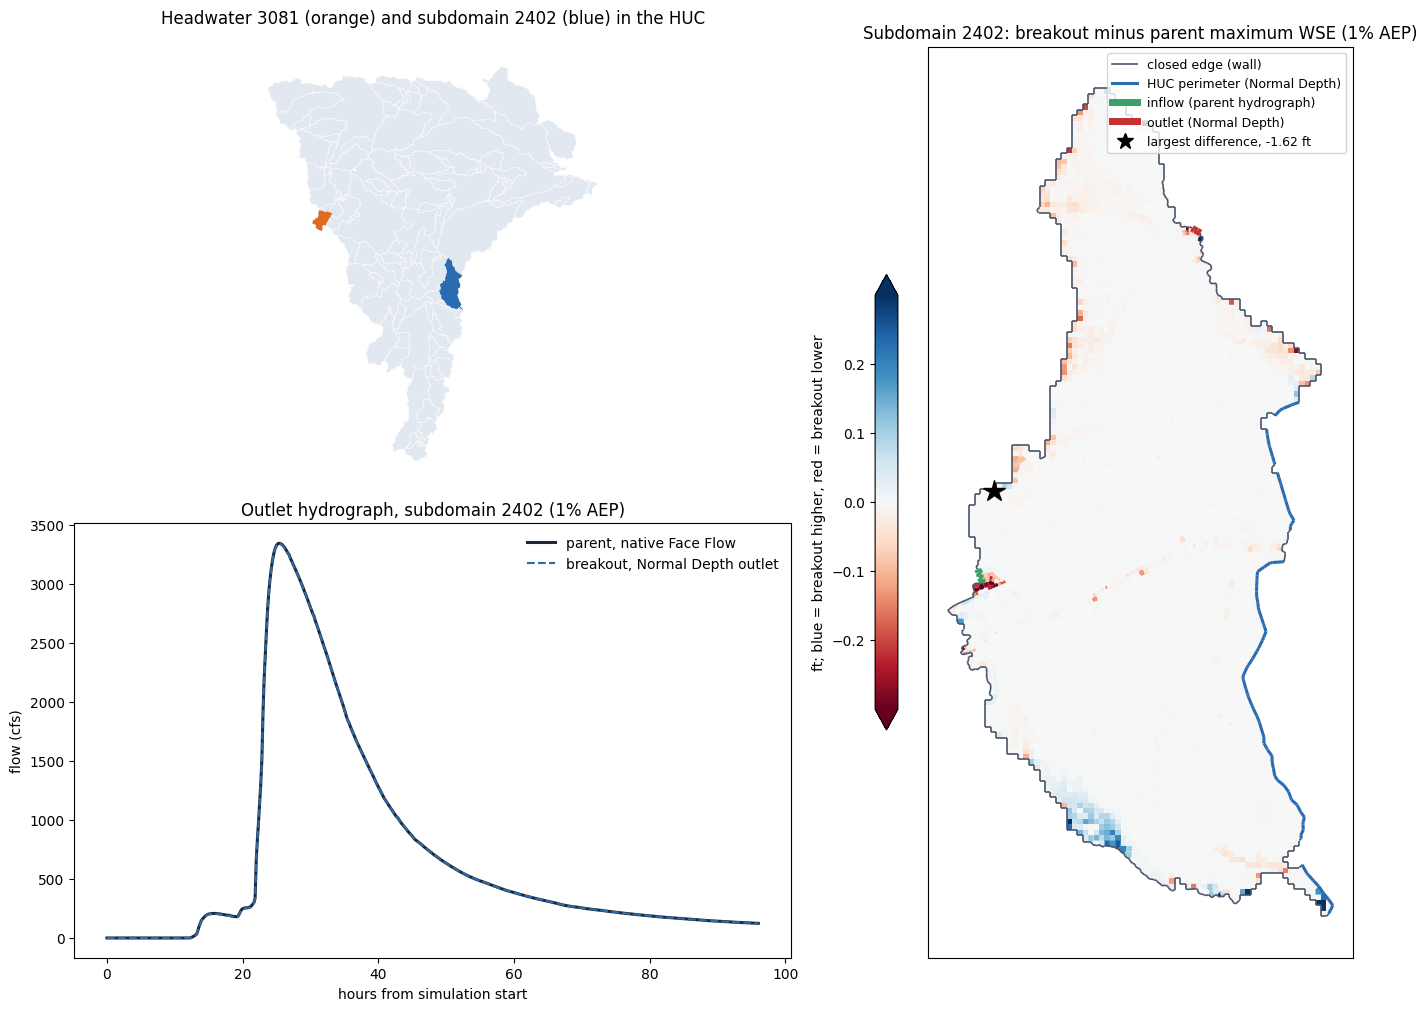

In [26]:
fig = plt.figure(figsize=(15, 10), constrained_layout=True)
grid = fig.add_gridspec(2, 2, width_ratios=[1.25, 1], height_ratios=[1, 1])
locator, flow_ax, diff_ax = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[:, 1])
tiers.plot(ax=locator, color="#E2E8F0", edgecolor="white", linewidth=0.3)
for sid, colour in ((HEADWATER, "#DD6B20"), (SECOND, "#2B6CB0")):
    subdomains[subdomains["subdomain_id"] == sid].plot(ax=locator, color=colour)
locator.set_title(f"Headwater {HEADWATER} (orange) and subdomain {SECOND} (blue) in the HUC")
locator.set_axis_off()
diff_ax.add_collection(PolyCollection([np.asarray(g.exterior.coords) for g in second_polys.geometry],
                                      array=second_cells["wse_diff_ft"].to_numpy(), cmap="RdBu", norm=norm,
                                      edgecolors="none"))
handles = []
for name, colour, width, label in (("closed", "#4A5568", 1.2, "closed edge (wall)"),
                                   ("HUC perimeter", "#2B6CB0", 2.2, "HUC perimeter (Normal Depth)"),
                                   ("inflow", "#38A169", 5.0, "inflow (parent hydrograph)"),
                                   ("outlet", "#C53030", 5.0, "outlet (Normal Depth)")):
    faces = edges2.face[edges2.kind == name]
    if len(faces):
        for part in seg(faces).geoms:
            diff_ax.plot(*np.asarray(part.coords).T, color=colour, linewidth=width, solid_capstyle="butt")
        handles.append(Line2D([], [], color=colour, linewidth=width, label=label))
k = second_abs.idxmax()
diff_ax.plot(second_cells.at[k, "x"], second_cells.at[k, "y"], marker="*", color="black", markersize=16, zorder=5)
handles.append(Line2D([], [], color="black", marker="*", linestyle="none", markersize=12,
                      label=f"largest difference, {second_cells.at[k, 'wse_diff_ft']:+.2f} ft"))
diff_ax.legend(handles=handles, loc="upper right", frameon=True, fontsize=9)
diff_ax.set_aspect("equal"); diff_ax.autoscale_view(); diff_ax.set_xticks([]); diff_ax.set_yticks([])
diff_ax.set_title(f"Subdomain {SECOND}: breakout minus parent maximum WSE (1% AEP)")
fig.colorbar(diff_ax.collections[0], ax=diff_ax, shrink=0.5, extend="both", location="left",
             label="ft; blue = breakout higher, red = breakout lower")
second_line = lines[int(SECOND)]
second_ids, second_flow = reader.series("Face Flow", second_line["faces"])
second_col = {int(f): i for i, f in enumerate(second_ids)}
second_parent_q = (second_flow[:, [second_col[int(f)] for f in second_line["faces"]]]
                   * np.asarray(second_line["signs"])).sum(axis=1)
second_h, second_q = _bc_flow(second_hdf, [f"Out_ND_{SECOND}"])
flow_ax.plot(parent_h, second_parent_q, color="#1F2937", lw=2.2, label="parent, native Face Flow")
flow_ax.plot(second_h, second_q, color="#2B6CB0", lw=1.5, ls="--", label="breakout, Normal Depth outlet")
flow_ax.set(xlabel="hours from simulation start", ylabel="flow (cfs)", title=f"Outlet hydrograph, subdomain {SECOND} (1% AEP)")
flow_ax.legend(frameon=False)
fig.savefig(FIG_DIR / "10_second_subdomain.png", dpi=130)
plt.show()

**Where it differs.** The differences fall at the subdomain's boundaries, as on
the headwater:

- **Closed edges:** the largest difference (−1.62 ft, star) is one cell at a
  notch in the western closed edge. Along the southwest edge a cluster of cells
  is higher by up to about 0.3 ft, where walls hold water the parent spilled
  across the divide.
- **Inflow line:** cells within 600 ft of it are lower by 0.08 ft on average
  (p95 0.33 ft). The inflow enters as one hydrograph spread across six faces,
  while in the parent the flow arrived with its own distribution across the
  channel. A faint trace of slightly lower water surfaces follows the main
  channel downstream.
- **Outlet:** six cells within 600 ft differ by more than 0.1 ft, the largest
  1.59 ft.

**The headwater's setback rule does not carry over.** About a dozen interior
cells more than 900 ft from the closed edges also exceed 0.1 ft, so a single setback
distance would leave almost nothing. For a larger subdomain, map the agreement
and read the project area against the map instead.

## 13. Runtime: why a breakout matters for project work

Project-level analysis means many runs: alternatives, sensitivity, design
iterations. The table compares the compute time HEC-RAS recorded for each run.

**Same hardware.** All runs here used CLB machines of the same 11th-generation
Intel architecture, which CLB operates as interchangeable. The breakouts ran on 2 cores, as
the parent re-run did and as an ensemble would. The parent re-run is therefore
the like-for-like reference. The delivered run (4 cores, the consultant's
workstation) is shown for context only. Each time is a single run; run-to-run
variability was not measured.

In [27]:
def run_record(path, label, where):
    with h5py.File(path, "r") as f:
        attrs = f["Results/Unsteady/Summary"].attrs
        text = lambda k: attrs[k].decode() if isinstance(attrs[k], bytes) else str(attrs[k])
        h, m, s = (int(v) for v in text("Computation Time Total").split(":"))
        return {"model": label, "where it ran": where, "cells": read_geometry(path, "SLDR_004").cell_count,
                "cores": int(attrs["Maximum number of cores"]), "compute_time_s": h * 3600 + m * 60 + s}


records = []
delivered_p01 = project_dir / "Input" / "SLDR_004.p01.hdf"
if delivered_p01.is_file():
    records.append(run_record(delivered_p01, "parent, as delivered", "consultant workstation"))
else:  # the delivered result is left in the archive; its recorded run summary:
    records.append({"model": "parent, as delivered", "where it ran": "consultant workstation",
                    "cells": delivered_geometry.cell_count, "cores": 4, "compute_time_s": 7 * 3600 + 50 * 60 + 41})
records.append(run_record(parent_1pct, "parent, Face Flow re-run", "CLB fleet"))
records.append(run_record(child_hdf, f"headwater {HEADWATER}, walls", "CLB workstation"))
records.append(run_record(open_hdf, f"headwater {HEADWATER}, closed-edge outflow", "CLB workstation"))
records.append(run_record(second_hdf, f"second subdomain {SECOND}, walls", "CLB workstation"))
runtime = pd.DataFrame(records)
runtime["compute_time"] = pd.to_timedelta(runtime["compute_time_s"], unit="s").astype(str).str.replace("0 days ", "")
reference_s = runtime.loc[1, "compute_time_s"]  # same 2 cores, same 11th-generation Intel machines
runtime["share of parent cells (%)"] = (100 * runtime["cells"] / delivered_geometry.cell_count).round(2)
runtime["speed-up vs parent at 2 cores"] = (reference_s / runtime["compute_time_s"]).round(1)
display(runtime[["model", "where it ran", "cells", "share of parent cells (%)", "cores", "compute_time",
                 "speed-up vs parent at 2 cores"]])
for label, row in ((f"headwater {HEADWATER}", 2), (f"subdomain {SECOND}", 4)):
    seconds = runtime.loc[row, "compute_time_s"]
    print(label + ": " + "; ".join(f"{n} alternatives {n * seconds / 3600:,.1f} h (parent {n * reference_s / 3600:,.0f} h)"
                                   for n in (10, 100)))

,model,where it ran,cells,share of parent cells (%),cores,compute_time,speed-up vs parent at 2 cores
0,"parent, as delivered",consultant workstation,794234,100.00,4,07:50:41,1.7
1,"parent, Face Flow re-run",CLB fleet,794234,100.00,2,13:00:26,1.0
2,"headwater 3081, walls",CLB workstation,2592,0.33,2,00:02:02,383.8
3,"headwater 3081, closed-edge outflow",CLB workstation,2592,0.33,2,00:01:20,585.3
4,"second subdomain 2402, walls",CLB workstation,9418,1.19,2,00:04:32,172.2


headwater 3081: 10 alternatives 0.3 h (parent 130 h); 100 alternatives 3.4 h (parent 1,301 h)
subdomain 2402: 10 alternatives 0.8 h (parent 130 h); 100 alternatives 7.6 h (parent 1,301 h)


**Run times, all on 2 cores.**

| Model | Cells | Compute time | Faster than the parent |
|---|---|---|---|
| Parent, Face Flow re-run (CLB fleet) | 794,234 | 13 h 0 min | reference |
| Headwater 3081, walls | 2,592 | 2 min 2 s | about 380 times |
| Headwater 3081, closed-edge outflow | 2,592 | 1 min 20 s | about 590 times |
| Subdomain 2402, walls | 9,418 | 4 min 32 s | about 170 times |

The speed-up is larger than the ratio of cell counts (306 and 84 times fewer
cells): the parent takes longer per cell. The workstation is shared, so
wall-clock times vary between runs: across the runs made for this notebook the
headwater took between 39 s and 2 min 2 s. Every breakout is held at the parent's
shortest step (15 s), so none of the gain comes from a longer time step.

**What it means for project work.**

- **Iterations.** Ten alternatives cost about 130 h of parent compute, against
  about 20 min on the headwater breakout or 45 min on subdomain 2402. A hundred
  cost about 1,300 h (54 days of one machine) against 3.4 h or 7.6 h.
- **One-time setup.** Running the parent once with Face Flow, the split-line
  search and partition (26.4 min) and authoring each breakout (about 2 min) are
  done once. Every later alternative then costs one breakout run, plus whatever
  editing the alternative needs.

These totals are linear estimates from single runs; an alternative that adds
cells or structures will cost more.

That is what makes iterating on alternatives practical; at 13 h per parent run
it is not.

## Findings and limits

**The split.** In HEC-RAS 6.4.1 the search accepted 116 normal-depth split lines
that hold in both the 1% and 0.2% AEP events, nested into 25 tiers. On the
delivered mesh it scored 1,304 pour points (54,376 scored steps and events) in
26.4 minutes (search and partition). Most candidates fail on outflow share or slope ratio. A
line placed where the channel is not yet carrying its catchment's flow, or
where the water surface slope departs from the bed slope, is rejected, which is
what a normal-depth boundary requires.

**The headwater breakout** reproduces the parent closely. It has 2,592 parent
cells over 5.9 sq mi and was cut, preprocessed and run in 6.4.1 at the
parent's 15 s step. Against the parent's 1% AEP run:

- **Maximum water surface:** within 0.0005 ft at the median and 0.017 ft at the
  95th percentile. Only 22 of 2,592 cells differ by more than 0.1 ft. The wet
  extent is identical.
- **Outlet:** NSE 0.9994 against the parent's native flow across the same
  faces; peak +2.1%, volume +2.0%.

**Where the breakout differs, and why (section 9).** The spatial diagnostics
place the largest differences at the two boundaries the cut introduces.

- **Closed edges that were slightly open in the parent.** Rain-on-grid sheet
  flow crossed the terrain divide: 2.6% of the outlet volume out, 0.8% in.
  Walling those faces raises maximum water surfaces just inside where the parent
  spilled out (up to +0.53 ft), and lowers them where the parent received water.
  The effect stays within a few hundred feet of the edge. The interior cells
  (85% of the cells) match to 0.009 ft at the 95th percentile.
- **One overbank face on the outlet line.** The line's third face crosses a
  perched overbank cell 8.7 ft above the channel bed. The parent drains it as a
  free outfall over the face's sill; as part of the Normal Depth line it drains
  more freely and peaks 1.15 ft lower. This is the single largest difference.
  Ending the outlet line at the channel banks should remove it (not tested
  here).
- **The channel itself.** At the outlet section the channel follows the fitted
  normal-depth rating through the rise, peak and main recession. On the
  low-flow tail the parent's downstream storage holds the stage 0.5 to 0.8 ft
  above normal depth. A normal-depth boundary cannot represent that tail.

**Walls are the better closed edge here (section 10).** The optional closed-edge
outflow (`closed_edge_outflow=True`, Normal Depth at 0.00033, kept 2 cells from
other BC lines) was also run on this headwater in HEC-RAS 6.4.1.

- **Over-release:** it passed 4.1% of the outlet volume across the divide,
  against the parent's net 1.7%.
- **Drained storage:** it emptied a pond held against the divide.
- **Worse agreement:** maximum WSE p95 0.032 ft and max 2.98 ft, against 0.017
  ft and 1.15 ft with walls; outlet volume −1.8%.

Walls give closer agreement, with differences of both signs that are largest
near the boundaries, so they are the default and the choice for this example. Turn the outflow on only where
the parent shows mostly one-way spill across a divide with no ponded storage
against it.

**Fit for project-level work inside the 0.1 ft envelope (section 11).** 98.9% of
the subdomain area agrees with the parent within 0.1 ft. Every cell more than
1,100 ft from a closed edge and from the outlet does, which is 77.8% of the
subdomain. A project whose area of interest lies inside that envelope can use
the breakout in place of the parent. In the project engineer's judgment, 0.1 ft
is adequate for most project-level analysis for regulatory purposes; suitability
for a given analysis still rests on its criteria and engineering review.

**A second, larger subdomain (section 12).** Subdomain 2402 is 18.9 sq mi of
local drainage along the main stem, its inflow and outlet lines 4.2 mi apart, with an inflow line forced with
the parent's own hydrograph. Its closed edges exchanged only 0.3% of the outlet
volume in the parent. It agrees as closely as the headwater: p95 0.018 ft over the cells wet in both
models, 98.7% of the area within 0.1 ft, and outlet NSE 0.999997. Its differences also sit at
its boundaries: one closed-edge cell (−1.62 ft), cells next to the inflow line,
and a few at the outlet.

**Runtime (section 13).** On the same 2 cores as the parent's 13 h run, and on
CLB machines of the same architecture, the headwater breakout ran in 2 min 2 s
and subdomain 2402 in 4 min 32 s: about 380 and 170 times faster. A hundred
alternatives become 3 to 8 hours of compute instead of about 54 days (linear estimates, excluding setup).
That makes the iterations of project-level work practical.

**Why the version and the time step matter.**

- **Version.** Running in the delivered version keeps the delivered mesh and
  its results comparable cell for cell. An earlier 6.6 run of this workflow
  first had to re-mesh the parent, because 6.6 rejects 48 cells with more than
  eight sides; it reached p95 0.018 ft and outlet NSE 0.89.
- **Time step.** Holding the child at the parent's shortest step matters as
  much. With the inherited Courant-adaptive step, a headwater differed by up to
  3.1 ft (p95 0.67 ft): the parent's step is forced down by its most restrictive
  cells elsewhere in the HUC, which a small child never sees.

**What this does not show.** The tiered run of the whole HUC, with hydrograph
hand-off into downstream subdomains, is implemented (`compute_subdomains`) but
is not run here.

**Limits of this release:**

- feet models only;
- the exact-cell cut accepts geometry from HEC-RAS 6.4.1 and 6.6 only;
- subdomains with holes, more than one part, or a structure on a split line
  are refused at planning;
- the inflow hand-off rewrites the downstream inline hydrograph and
  preprocesses again.

**Roadmap:**

- end outlet lines at the channel banks when an end face is a perched
  overbank sill;
- an isolated subdomain around a project point or polygon, with its
  downstream and upstream boundary lines found automatically;
- interior subdomains with holes;
- SI units.

## Related work

Garcia et al. (2023) split HEC-RAS 2D models of urban watersheds in Houston into
independent sub-domains, so that a localized change, such as filling a detention
pond, needs re-computation only in the sub-domain it affects. In their discrete
approach, 25 separately meshed 2D modules were coupled directly to their
neighbors through HEC-RAS SA/2D Area Connections rather than through exchanged
boundary conditions. In their abstract approach, any contiguous set of cells is
cut from the computed parent model, keeping the parent's cells, and forced with
the parent's stored flow across each boundary face. Both closely approximated
re-running the whole model.

The method demonstrated here was implemented from a conceptual approach starting
with locating idealized normal depth-approximated boundaries where they exist,
and leveraging them for subdomain analysis. The boundaries are located by
sampling transverse face flow on lines grown from points along hydrologically
delineated channel polygons. William Katzenmeyer, P.E. (CLB Engineering)
specified that idea, and it was implemented with the ras-commander API and agent
tools. Each subdomain here is a separate model with its own normal-depth outlet
and inflow hydrograph, so it can run without the parent's stored results. Both
cookie-cutter extraction and re-meshing of subdomains were tested; cookie-cutter
extraction reproduced the parent's results more closely, as expected, because it
keeps the parent's cells.

- Garcia, M., Juan, A., Doss-Gollin, J., & Bedient, P. (2023). Leveraging mesh
  modularization to lower the computational cost of localized updates to
  regional 2D hydrodynamic model outputs. *Engineering Applications of
  Computational Fluid Mechanics*, 17(1), 2225584.
  https://doi.org/10.1080/19942060.2023.2225584

## Logical extensions

This notebook covers only the development of the method and project-level
subdomaining of eBFE models. Three extensions follow from it:

- **Hydrologic boundaries in the mesh.** Re-mesh subdomains, or enforce
  breaklines along the hydrologic boundaries, so that the divide between
  subdomains lies on cell faces that follow the terrain. That reduces the
  sheet-flow exchange across closed edges, which is the largest source of
  difference in both runs here.
- **Combined subbasins.** Where the parent shows significant flow between
  subbasins, combine them into one subdomain. That removes the closed edge
  across which the flow passes and improves overall hydraulic performance.
- **Multi-model orchestration.** Run the whole HUC as tiers of subdomains, each
  handing its outlet hydrograph to the next. For this HUC model, that gives a
  modest 20 to 30% improvement in end-to-end runtime, and headwater subdomains
  return results almost immediately.